<a href="https://colab.research.google.com/github/Prayansh-builds/ai-colorist/blob/main/ai_colorist_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (1600, 1200, 3) | Min: 0.0 | Max: 1.0


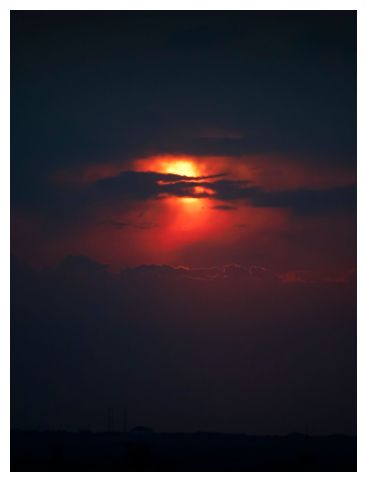

In [ ]:
# Connect Google Drive so Colab can see your photos
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import cv2
import matplotlib.pyplot as plt

# Path to one of your test photos
path = "/content/drive/MyDrive/ai-colorist/test_images/photo1.jpg"

# Load the photo
img_bgr = cv2.imread(path)
if img_bgr is None:
    raise FileNotFoundError("Photo not found. Check the folder and file name.")

# OpenCV loads colours as Blue-Green-Red, so flip to Red-Green-Blue
# Then divide by 255 so every value sits between 0 and 1
img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

# Print the photo's shape and brightest/darkest values
print("Shape:", img.shape, "| Min:", img.min(), "| Max:", img.max())

# Show it
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.show()


In [ ]:
# Connect Drive again (Colab forgets it when it disconnects)
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import cv2
import os
import matplotlib.pyplot as plt

# Change to "test_images_1600" if you made the resized copies
FOLDER = "/content/drive/MyDrive/ai-colorist/test_images"

# List every photo in the folder
files = [f for f in sorted(os.listdir(FOLDER))
         if f.lower().endswith((".jpg", ".jpeg", ".png"))]
print(len(files), "photos found")

def load_image(name):
    bgr = cv2.imread(os.path.join(FOLDER, name))
    if bgr is None:
        raise FileNotFoundError("Cannot open " + name)
    # Flip to RGB and scale every value to the 0-1 range
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

def show_many(images, titles):
    # Show several images in one row
    plt.figure(figsize=(16, 4))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(np.clip(im, 0, 1))
        plt.title(t)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
22 photos found


In [ ]:
# ---------- Helpers ----------
def srgb_to_linear(x):
    # Photos store brightness in a squashed way. This undoes it,
    # so exposure maths behaves like real light.
    return np.where(x <= 0.04045, x / 12.92, ((x + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(x):
    # Squash it back so it looks right on screen
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, x * 12.92, 1.055 * (x ** (1 / 2.4)) - 0.055)

def luma(img):
    # How bright each pixel feels to the eye (green counts the most)
    return (0.2126 * img[..., 0] + 0.7152 * img[..., 1] + 0.0722 * img[..., 2])[..., None]

# ---------- The dials ----------
def exposure(img, stops):
    # +1 stop = twice the light
    lin = srgb_to_linear(img) * (2.0 ** stops)
    return linear_to_srgb(lin)

def contrast(img, amount):
    if amount >= 0:
        s = img * img * (3 - 2 * img)       # a gentle S-curve
        out = img + amount * (s - img)       # blend toward the S-curve
    else:
        out = (img - 0.5) * (1 + amount) + 0.5   # flatten toward grey
    return np.clip(out, 0, 1)

def saturation(img, amount):
    gray = luma(img)                         # the colourless version
    return np.clip(gray + (img - gray) * (1 + amount), 0, 1)

def temperature(img, amount):
    out = img.copy()
    out[..., 0] *= 1 + 0.15 * amount         # more red = warmer
    out[..., 2] *= 1 - 0.15 * amount         # less blue = warmer
    return np.clip(out, 0, 1)

def tint(img, amount):
    out = img.copy()
    out[..., 1] *= 1 - 0.15 * amount         # less green = more magenta
    return np.clip(out, 0, 1)

def shadows(img, amount):
    weight = (1 - luma(img)) ** 2            # strong in dark areas, weak in bright
    return np.clip(img * (1 + amount * weight), 0, 1)

def highlights(img, amount):
    weight = luma(img) ** 2                  # strong in bright areas, weak in dark
    return np.clip(img * (1 + amount * weight), 0, 1)

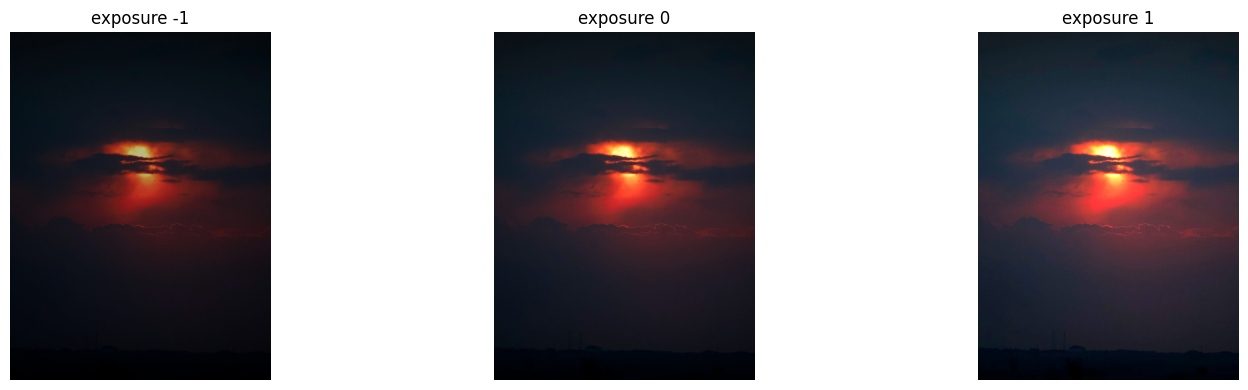

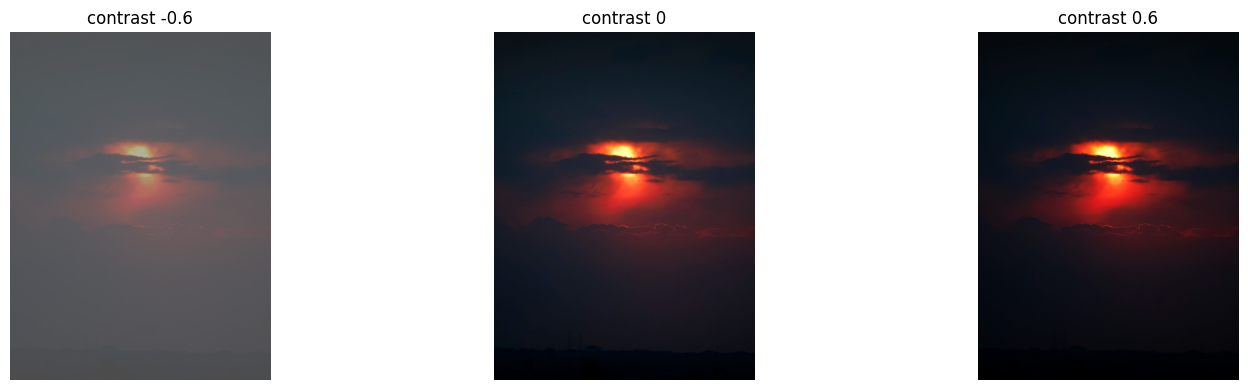

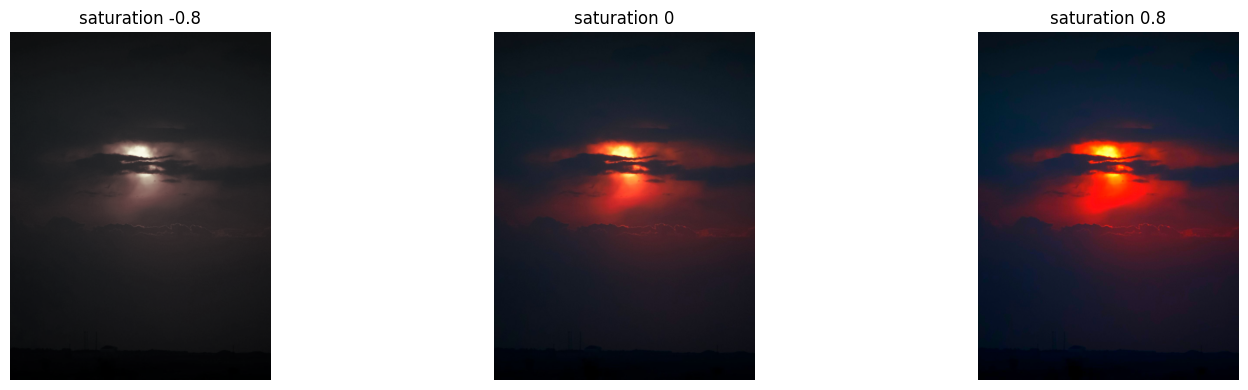

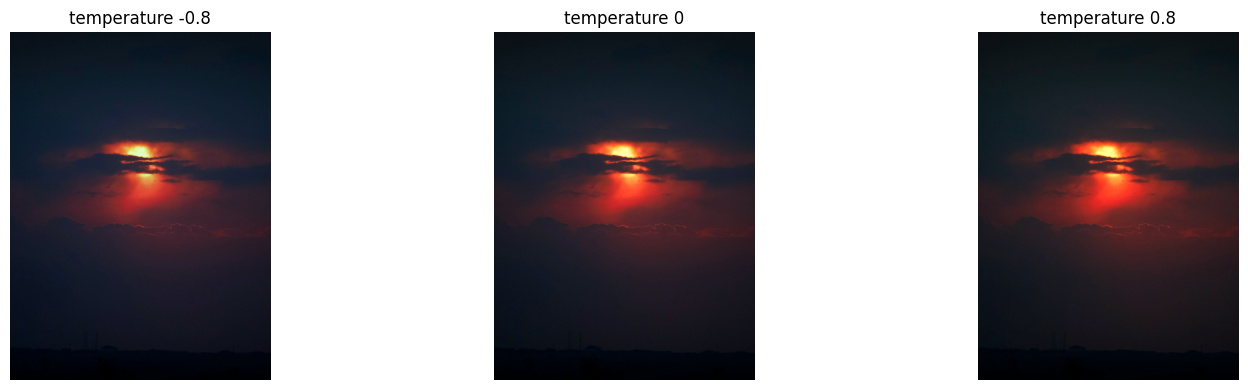

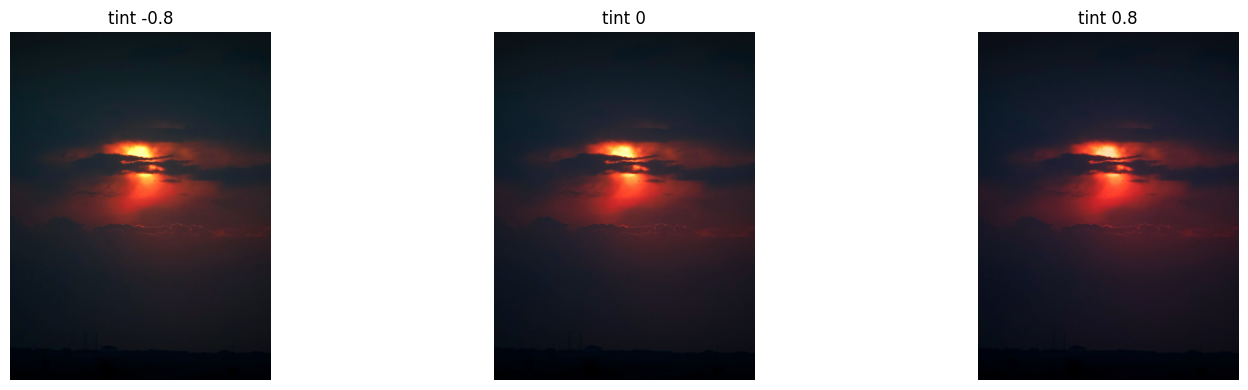

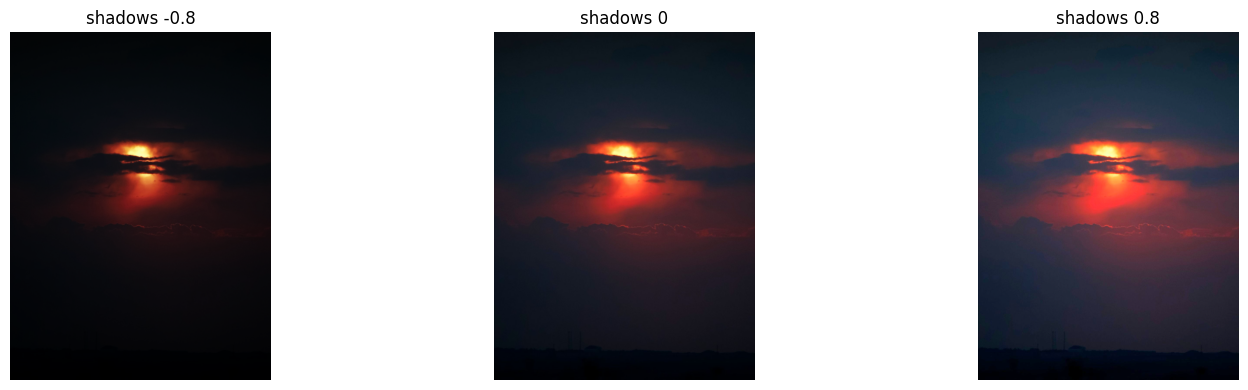

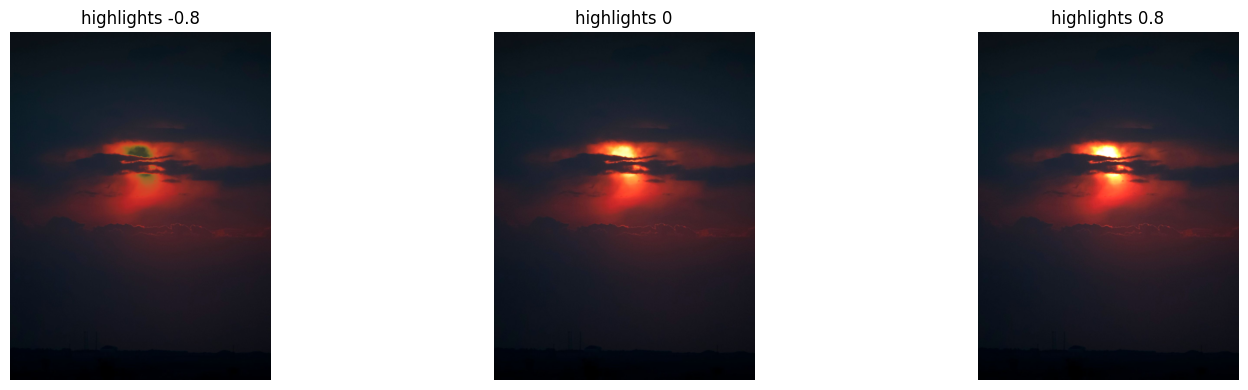

In [ ]:
img = load_image(files[0])      # try files[1], files[2], ... for other photos

def strip(dial, values):
    # Show the same photo at three dial settings
    show_many([dial(img, v) for v in values],
              [dial.__name__ + " " + str(v) for v in values])

strip(exposure,    [-1, 0, 1])
strip(contrast,    [-0.6, 0, 0.6])
strip(saturation,  [-0.8, 0, 0.8])
strip(temperature, [-0.8, 0, 0.8])
strip(tint,        [-0.8, 0, 0.8])
strip(shadows,     [-0.8, 0, 0.8])
strip(highlights,  [-0.8, 0, 0.8])

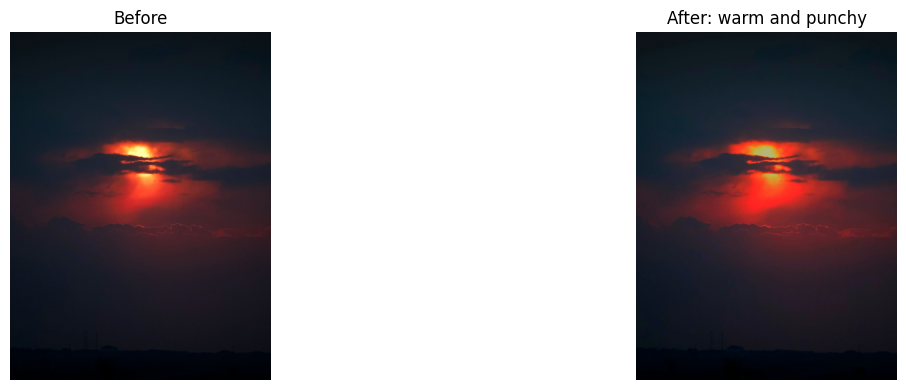

In [ ]:
def grade(img, exposure_stops=0, contrast_amt=0, saturation_amt=0,
          temp=0, tint_amt=0, shadows_amt=0, highlights_amt=0):
    # Keep every dial inside its safe range
    clamp = lambda v, lo, hi: float(np.clip(v, lo, hi))

    out = exposure(img, clamp(exposure_stops, -3, 3))
    out = temperature(out, clamp(temp, -1, 1))
    out = tint(out, clamp(tint_amt, -1, 1))
    out = contrast(out, clamp(contrast_amt, -1, 1))
    out = shadows(out, clamp(shadows_amt, -1, 1))
    out = highlights(out, clamp(highlights_amt, -1, 1))
    out = saturation(out, clamp(saturation_amt, -1, 1))
    return out

# A quick "warm and punchy" look
warm = grade(img, exposure_stops=0.2, contrast_amt=0.25, saturation_amt=0.1,
             temp=0.4, shadows_amt=0.3, highlights_amt=-0.3)

show_many([img, warm], ["Before", "After: warm and punchy"])

In [ ]:
def split_view(before, after, split):
    # Left of the line shows the original, right of it shows the graded photo
    h, w = before.shape[:2]
    x = int(w * split)
    out = after.copy()
    out[:, :x] = before[:, :x]
    # Draw a thin white divider line
    line = max(1, w // 400)
    out[:, max(0, x - line):x + line] = 1.0
    return out

In [ ]:
# Makes a small preview copy of a photo, so everything runs fast
def small(img, max_side=800):
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1:
        return cv2.resize(img, (int(w * scale), int(h * scale)),
                          interpolation=cv2.INTER_AREA)
    return img

In [ ]:
import ipywidgets as widgets

PHOTO_INDEX = 0                          # which photo to work on (0 = first one)
img = small(load_image(files[PHOTO_INDEX]))

last = {}                                # remembers your latest slider values

def S(label, lo, hi):
    # Builds one slider. It updates when you let go, which keeps it fast
    return widgets.FloatSlider(
        value=0, min=lo, max=hi, step=0.05, description=label,
        continuous_update=False,
        style={"description_width": "80px"},
        layout=widgets.Layout(width="450px"))

@widgets.interact(
    split=widgets.FloatSlider(value=0.5, min=0, max=1, step=0.01,
                              description="Split", continuous_update=False,
                              style={"description_width": "80px"},
                              layout=widgets.Layout(width="450px")),
    exposure_stops=S("Exposure", -3, 3),
    contrast_amt=S("Contrast", -1, 1),
    saturation_amt=S("Saturation", -1, 1),
    temp=S("Temperature", -1, 1),
    tint_amt=S("Tint", -1, 1),
    shadows_amt=S("Shadows", -1, 1),
    highlights_amt=S("Highlights", -1, 1))
def viewer(split, exposure_stops, contrast_amt, saturation_amt,
           temp, tint_amt, shadows_amt, highlights_amt):
    values = dict(exposure_stops=exposure_stops, contrast_amt=contrast_amt,
                  saturation_amt=saturation_amt, temp=temp, tint_amt=tint_amt,
                  shadows_amt=shadows_amt, highlights_amt=highlights_amt)
    last.clear()
    last.update(values)                  # save the settings for the export step

    graded = grade(img, **values)
    plt.figure(figsize=(9, 6))
    plt.imshow(np.clip(split_view(img, graded, split), 0, 1))
    plt.axis("off")
    plt.show()

interactive(children=(FloatSlider(value=0.5, continuous_update=False, description='Split', layout=Layout(width…

In [ ]:
out_dir = "/content/drive/MyDrive/ai-colorist/outputs"
os.makedirs(out_dir, exist_ok=True)

full = load_image(files[PHOTO_INDEX])        # the original, full-size photo
graded_full = grade(full, **last)            # the same slider settings

# Convert back from 0-1 numbers to a normal photo file
rgb8 = (np.clip(graded_full, 0, 1) * 255).astype(np.uint8)
bgr = cv2.cvtColor(rgb8, cv2.COLOR_RGB2BGR)
save_path = os.path.join(out_dir, "graded_" + files[PHOTO_INDEX])
cv2.imwrite(save_path, bgr, [cv2.IMWRITE_JPEG_QUALITY, 95])
print("Saved:", save_path)
print("Settings used:", last)

Saved: /content/drive/MyDrive/ai-colorist/outputs/graded_photo1.jpg
Settings used: {'exposure_stops': 0.0, 'contrast_amt': 0.0, 'saturation_amt': 0.0, 'temp': 0.0, 'tint_amt': 0.0, 'shadows_amt': 0.0, 'highlights_amt': 0.0}


In [ ]:
import json, colorsys
from scipy.interpolate import PchipInterpolator

def curve(img, points):
    # points = list of (input, output) pairs, each between 0 and 1
    # Example: [(0,0), (0.25,0.18), (0.75,0.82), (1,1)] = an S-curve
    pts = sorted((float(x), float(y)) for x, y in points)
    if pts[0][0] > 0:  pts.insert(0, (0.0, 0.0))     # make sure it starts at 0
    if pts[-1][0] < 1: pts.append((1.0, 1.0))        # and ends at 1
    f = PchipInterpolator([p[0] for p in pts], [p[1] for p in pts])  # smooth line through points
    lut_x = np.linspace(0, 1, 1024)                  # a fast lookup table
    lut_y = np.clip(f(lut_x), 0, 1)
    return np.interp(np.clip(img, 0, 1), lut_x, lut_y).astype(np.float32)

def fade(img, amount):
    # Lifts the blacks: the faded "film" look
    lift = 0.10 * amount
    return np.clip(lift + img * (1 - lift), 0, 1)

In [ ]:
def hue_to_offset(hue_deg, strength):
    # Turns a colour angle and a strength into a small push toward that colour
    r, g, b = colorsys.hsv_to_rgb((hue_deg % 360) / 360.0, 1.0, 1.0)
    v = np.array([r, g, b], dtype=np.float32)
    v = v - v.mean()                     # change colour only, not brightness
    return v * float(np.clip(strength, 0, 1)) * 0.15

def color_wheels(img, shadows=(0, 0), mids=(0, 0), highlights=(0, 0)):
    # Each wheel = (hue in degrees, strength from 0 to 1)
    l = luma(img)
    w_shadow = (1 - l) ** 2              # strong in dark areas
    w_high = l ** 2                      # strong in bright areas
    w_mid = 1 - w_shadow - w_high        # whatever is left in the middle
    out = (img + w_shadow * hue_to_offset(*shadows)
               + w_mid * hue_to_offset(*mids)
               + w_high * hue_to_offset(*highlights))
    return np.clip(out, 0, 1)

In [ ]:
HUES = {"red": 0, "orange": 30, "yellow": 60, "green": 120,
        "aqua": 180, "blue": 240, "purple": 275, "magenta": 320}

def hsl(img, color, hue_shift=0, sat=0, lum=0, width=40):
    # Edits only pixels near one colour: hue_shift in degrees, sat and lum from -1 to 1
    hsv = cv2.cvtColor(np.clip(img, 0, 1).astype(np.float32), cv2.COLOR_RGB2HSV)
    H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    d = np.abs(H - HUES[color])
    d = np.minimum(d, 360 - d)                       # distance around the colour circle
    w = np.where(d < width, 0.5 * (1 + np.cos(np.pi * d / width)), 0.0) * S   # soft edge; greys untouched
    H = (H + hue_shift * w) % 360
    S = np.clip(S * (1 + sat * w), 0, 1)
    V = np.clip(V * (1 + lum * w * 0.5), 0, 1)
    out = cv2.cvtColor(np.stack([H, S, V], axis=-1).astype(np.float32), cv2.COLOR_HSV2RGB)
    return np.clip(out, 0, 1)

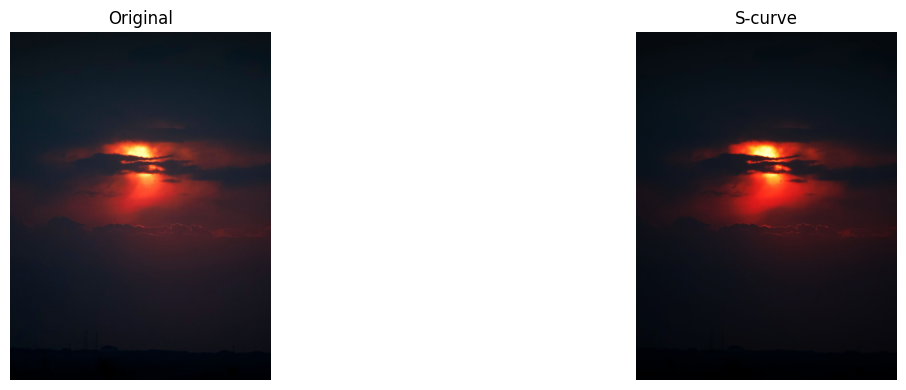

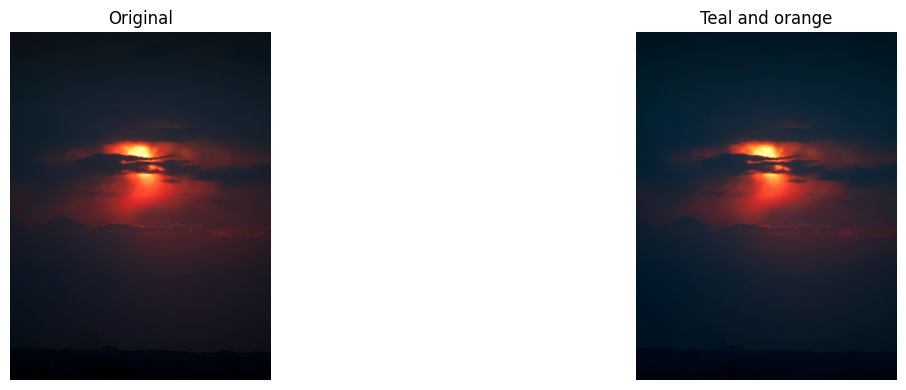

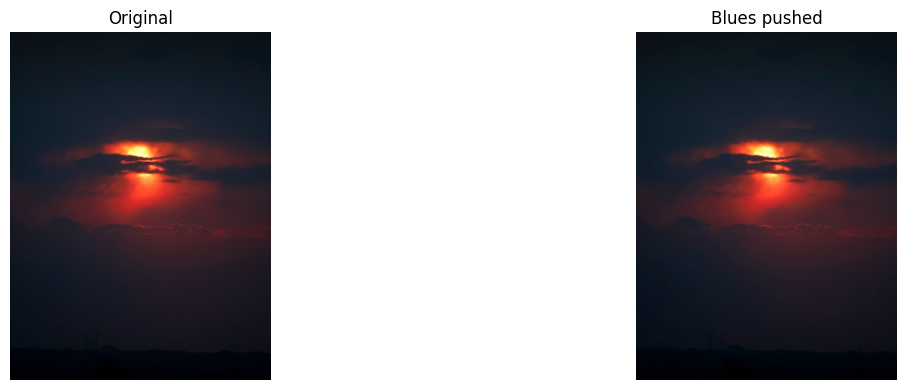

In [ ]:
img = small(load_image(files[0]))

# Curves: S-curve
show_many([img, curve(img, [(0, 0), (0.25, 0.18), (0.75, 0.82), (1, 1)])],
          ["Original", "S-curve"])

# Colour wheels: teal shadows, orange highlights
show_many([img, color_wheels(img, shadows=(195, 0.6), highlights=(30, 0.5))],
          ["Original", "Teal and orange"])

# HSL: bluer sky with a slight teal shift
show_many([img, hsl(img, "blue", hue_shift=-15, sat=0.5)],
          ["Original", "Blues pushed"])

In [ ]:
def grade(img, exposure_stops=0, contrast_amt=0, saturation_amt=0,
          temp=0, tint_amt=0, shadows_amt=0, highlights_amt=0,
          curve_pts=None, wheels=None, hsl_edits=None, fade_amt=0):
    clamp = lambda v, lo, hi: float(np.clip(v, lo, hi))

    out = exposure(img, clamp(exposure_stops, -3, 3))
    out = temperature(out, clamp(temp, -1, 1))
    out = tint(out, clamp(tint_amt, -1, 1))
    out = contrast(out, clamp(contrast_amt, -1, 1))
    if curve_pts:
        out = curve(out, curve_pts)
    out = shadows(out, clamp(shadows_amt, -1, 1))
    out = highlights(out, clamp(highlights_amt, -1, 1))
    if wheels:
        out = color_wheels(out, **wheels)
    if hsl_edits:
        for e in hsl_edits:
            out = hsl(out, e["color"], clamp(e.get("hue", 0), -30, 30),
                      clamp(e.get("sat", 0), -1, 1), clamp(e.get("lum", 0), -1, 1))
    out = saturation(out, clamp(saturation_amt, -1, 1))
    out = fade(out, clamp(fade_amt, 0, 1))
    return out

In [ ]:
PRESETS = {
    "teal_orange": dict(contrast_amt=0.25, saturation_amt=0.05,
                        wheels={"shadows": [195, 0.6], "highlights": [30, 0.5]}),
    "film_fade":   dict(contrast_amt=-0.1, saturation_amt=-0.15, fade_amt=0.5, temp=0.15,
                        curve_pts=[(0, 0), (0.25, 0.22), (0.75, 0.78), (1, 1)]),
    "warm_golden": dict(exposure_stops=0.15, temp=0.45, tint_amt=0.05,
                        shadows_amt=0.2, highlights_amt=-0.2,
                        wheels={"highlights": [40, 0.4]}),
    "cool_moody":  dict(exposure_stops=-0.3, contrast_amt=0.3, saturation_amt=-0.2,
                        temp=-0.5, wheels={"shadows": [215, 0.5]}),
}

def apply_preset(img, name, strength=1.0):
    # strength 0 = original, 1 = full look
    graded = grade(img, **PRESETS[name])
    return np.clip(img + strength * (graded - img), 0, 1)

In [ ]:
path = "/content/drive/MyDrive/ai-colorist/presets.json"
with open(path, "w") as f:
    json.dump(PRESETS, f, indent=2)
print("Saved", len(PRESETS), "presets")

Saved 4 presets


In [ ]:
@widgets.interact(
    preset=widgets.Dropdown(options=list(PRESETS), description="Look"),
    strength=widgets.FloatSlider(value=1, min=0, max=1, step=0.05,
                                 description="Strength", continuous_update=False),
    split=widgets.FloatSlider(value=0.5, min=0, max=1, step=0.01,
                              description="Split", continuous_update=False))
def preset_viewer(preset, strength, split):
    out = apply_preset(img, preset, strength)
    plt.figure(figsize=(9, 6))
    plt.imshow(np.clip(split_view(img, out, split), 0, 1))
    plt.axis("off")
    plt.show()

interactive(children=(Dropdown(description='Look', options=('teal_orange', 'film_fade', 'warm_golden', 'cool_m…

In [ ]:
MODELS = ["gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.5-flash", "gemini-3.1-flash-lite"]

def generate(contents, config=None, tries=3):
    for model in MODELS:
        for attempt in range(tries):
            try:
                reply = client.models.generate_content(
                    model=model, contents=contents, config=config)
                print("(used", model + ")")
                return reply.text or ""
            except Exception as e:
                msg = str(e)
                print(f"{model}, attempt {attempt + 1} failed:", msg[:120])
                if "404" in msg or "NOT_FOUND" in msg:
                    break                          # wrong name: go to the next model
                time.sleep(4 * (attempt + 1))      # wait a bit longer each time
    return ""

print(generate("Say hi in five words."))

gemini-3.8-flash, attempt 1 failed: name 'client' is not defined


NameError: name 'time' is not defined

In [ ]:
# Makes a small preview copy of a photo, so everything runs fast
def small(img, max_side=800):
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1:
        return cv2.resize(img, (int(w * scale), int(h * scale)),
                          interpolation=cv2.INTER_AREA)
    return img

# Check which earlier cells still need to run
needed = ["files", "load_image", "show_many", "luma", "exposure", "contrast",
          "saturation", "temperature", "tint", "shadows", "highlights",
          "curve", "fade", "color_wheels", "hsl", "HUES", "grade",
          "PRESETS", "apply_preset", "split_view", "widgets"]
missing = [n for n in needed if n not in globals()]
print("Missing:", missing if missing else "nothing, all good")

In [ ]:
def describe_photo(img):
    l = luma(img)[..., 0]
    p5, p50, p95 = np.percentile(l, [5, 50, 95])
    colorful = np.mean(np.max(img, axis=2) - np.min(img, axis=2))
    warmth = np.mean(img[..., 0]) - np.mean(img[..., 2])
    return (f"median brightness {p50:.2f} (0=black, 1=white); darkest 5% at {p5:.2f}; "
            f"brightest 5% at {p95:.2f}; colourfulness {colorful:.2f}; "
            f"warmth {warmth:+.2f} (positive=warm/orange, negative=cool/blue)")

print(describe_photo(small(load_image(files[0]))))

In [ ]:
SYSTEM_PROMPT = """You are the brain of an AI colour-grading tool. The user types a request; you reply with a JSON plan that a program applies to the photo. Reply with JSON only: no words before or after it, no code fences.

Format:
{"settings": {...}, "preset": null, "preset_strength": 1.0, "explanation": "one short sentence"}

"settings" may contain only these keys (leave out any you do not need):
- exposure_stops: -3 to 3 (+0.3 is a small brightening)
- contrast_amt: -1 to 1
- saturation_amt: -1 to 1
- temp: -1 to 1 (positive = warmer/orange, negative = cooler/blue)
- tint_amt: -1 to 1 (positive = magenta, negative = green)
- shadows_amt: -1 to 1 (positive lifts dark areas)
- highlights_amt: -1 to 1 (negative recovers bright areas)
- fade_amt: 0 to 1 (lifted blacks, film look)
- curve_pts: list of [input, output] pairs from 0 to 1, e.g. [[0,0],[0.25,0.2],[0.75,0.8],[1,1]]
- wheels: {"shadows": [hue_degrees, strength], "mids": [hue_degrees, strength], "highlights": [hue_degrees, strength]}, strength 0 to 1 (use 0.2 to 0.5)
- hsl_edits: list of {"color": "red|orange|yellow|green|aqua|blue|purple|magenta", "hue": -30 to 30, "sat": -1 to 1, "lum": -1 to 1}

Hue angles: 0 red, 30 orange, 60 yellow, 120 green, 190 teal, 240 blue, 300 magenta.

"preset" is null or one of: PRESET_LIST. Use a preset only when the user asks for that style. preset_strength is 0 to 1.

Rules for good taste:
1. Be subtle. Typical values are 0.1 to 0.35. "A little" = 0.1 to 0.15, normal = 0.2 to 0.35, "a lot" or "very" = 0.4 to 0.6. Never go above 0.6 unless the user clearly asks for an extreme look.
2. Use the photo stats. If the median brightness is above 0.6, brighten less. If it is below 0.35, brighten more. Do not push highlights if the brightest 5% is already above 0.95. Do not add warmth to an already warm photo.
3. Prefer a few settings over many. Do not touch dials the request does not imply.
4. Protect skin tones: no strong saturation boosts on orange, and keep teal in the shadows, not the midtones.
5. If the request is unclear or not about the colour or light of a photo, return {"settings": {}, "preset": null, "preset_strength": 1.0, "explanation": "I could not tell what to change."}
6. If the user asks for one region (sky, face, background), apply a mild global version instead and say in the explanation that region editing is not available yet.
"""
SYSTEM_PROMPT = SYSTEM_PROMPT.replace("PRESET_LIST", ", ".join(PRESETS))

In [ ]:
def num(v, lo, hi, default=0.0):
    try:
        return float(np.clip(float(v), lo, hi))
    except (TypeError, ValueError):
        return default

RANGES = {"exposure_stops": (-3, 3), "contrast_amt": (-1, 1), "saturation_amt": (-1, 1),
          "temp": (-1, 1), "tint_amt": (-1, 1), "shadows_amt": (-1, 1),
          "highlights_amt": (-1, 1), "fade_amt": (0, 1)}

def clean_plan(raw):
    settings = {}
    given = raw.get("settings", {})
    if not isinstance(given, dict):
        given = {}
    for key, value in given.items():
        if key in RANGES:
            settings[key] = num(value, *RANGES[key])

        elif key == "curve_pts":
            try:
                pts = {num(a, 0, 1): num(b, 0, 1) for a, b in value}   # removes repeated inputs
                if 2 <= len(pts) <= 8:
                    settings[key] = sorted(pts.items())
            except (TypeError, ValueError):
                pass

        elif key == "wheels" and isinstance(value, dict):
            wheels = {}
            for name in ("shadows", "mids", "highlights"):
                if name in value:
                    try:
                        hue, strength = value[name]
                        wheels[name] = (float(hue) % 360, num(strength, 0, 1))
                    except (TypeError, ValueError):
                        pass
            if wheels:
                settings[key] = wheels

        elif key == "hsl_edits" and isinstance(value, list):
            edits = []
            for e in value[:8]:
                if isinstance(e, dict) and e.get("color") in HUES:
                    edits.append(dict(color=e["color"],
                                      hue=num(e.get("hue", 0), -30, 30),
                                      sat=num(e.get("sat", 0), -1, 1),
                                      lum=num(e.get("lum", 0), -1, 1)))
            if edits:
                settings[key] = edits
        # anything else is ignored

    preset = raw.get("preset")
    if not (isinstance(preset, str) and preset in PRESETS):
        preset = None
    return dict(settings=settings, preset=preset,
                preset_strength=num(raw.get("preset_strength", 1.0), 0, 1, 1.0),
                explanation=str(raw.get("explanation", ""))[:200])

def parse_json(text):
    start, end = text.find("{"), text.rfind("}")      # ignore stray words around the JSON
    if start == -1 or end == -1:
        raise ValueError("no JSON found")
    return json.loads(text[start:end + 1])

In [ ]:
def call_gemini(command, img):
    return generate(
        f"Photo stats: {describe_photo(img)}\nUser request: {command}",
        types.GenerateContentConfig(system_instruction=SYSTEM_PROMPT,
                                    response_mime_type="application/json"))

def ask_brain(command, img):
    text = call_gemini(command, img)
    try:
        return clean_plan(parse_json(text))
    except Exception as e:
        print("Could not read the brain's answer:", e)
        print(text)
        return dict(settings={}, preset=None, preset_strength=1.0,
                    explanation="Could not understand the plan, so the photo is unchanged.")

def run_command(img, command):
    plan = ask_brain(command, img)
    out = img
    if plan["preset"]:
        out = apply_preset(out, plan["preset"], plan["preset_strength"])
    out = grade(out, **plan["settings"])
    print("Brain says:", plan["explanation"])
    print("Settings:", json.dumps(plan["settings"], indent=1))
    return out, plan

# First test
img = small(load_image(files[0]))
out, plan = run_command(img, "make it a little warmer and brighter")
show_many([img, out], ["Before", "After"])

In [ ]:
SYSTEM_PROMPT += """
7. Exposure is measured in stops, so use smaller numbers than for other dials: "a little" = 0.1 to 0.25, normal = 0.3 to 0.5, "a lot" = 0.6 to 1.0. On a dark photo, prefer raising shadows_amt over large exposure increases, so the bright parts do not burn out.
"""

In [ ]:
cmd_box = widgets.Text(placeholder="Type a command, e.g. make it moody",
                       layout=widgets.Layout(width="520px"))
run_btn = widgets.Button(description="Grade it", button_style="primary")
out_area = widgets.Output()

def on_click(_):
    with out_area:
        out_area.clear_output(wait=True)
        result, plan = run_command(img, cmd_box.value)
        show_many([img, result], ["Before", "After"])

run_btn.on_click(on_click)
display(widgets.VBox([cmd_box, run_btn, out_area]))

In [ ]:
needed = ["skin_mask", "protect_skin", "clip_stats", "safe_finish", "build_edit",
          "Session", "export_full", "ask_brain", "grade", "show_many", "widgets",
          "files", "small", "load_image", "json", "os", "cv2", "np", "plt"]
print("Missing:", [n for n in needed if n not in globals()])

Missing: ['skin_mask', 'protect_skin', 'clip_stats', 'safe_finish', 'build_edit', 'Session', 'export_full', 'ask_brain']


In [ ]:
needed = ["client", "types", "time", "generate", "describe_photo", "SYSTEM_PROMPT",
          "clean_plan", "parse_json", "PRESETS", "apply_preset", "grade"]
print("Missing:", [n for n in needed if n not in globals()])

Missing: ['client', 'types', 'time', 'describe_photo', 'SYSTEM_PROMPT', 'clean_plan', 'parse_json']


In [ ]:
!pip install -q google-genai
import json, time
from google import genai
from google.genai import types
from google.colab import userdata

# ---------- 5C: connect to Gemini ----------
client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

MODELS = ["gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.5-flash", "gemini-3.1-flash-lite"]

def generate(contents, config=None, tries=3):
    for model in MODELS:
        for attempt in range(tries):
            try:
                reply = client.models.generate_content(
                    model=model, contents=contents, config=config)
                print("(used", model + ")")
                return reply.text or ""
            except Exception as e:
                msg = str(e)
                print(f"{model}, attempt {attempt + 1} failed:", msg[:120])
                if "404" in msg or "NOT_FOUND" in msg:
                    break
                time.sleep(4 * (attempt + 1))
    return ""

# ---------- 5D: the photo's numbers ----------
def describe_photo(img):
    l = luma(img)[..., 0]
    p5, p50, p95 = np.percentile(l, [5, 50, 95])
    colorful = np.mean(np.max(img, axis=2) - np.min(img, axis=2))
    warmth = np.mean(img[..., 0]) - np.mean(img[..., 2])
    return (f"median brightness {p50:.2f} (0=black, 1=white); darkest 5% at {p5:.2f}; "
            f"brightest 5% at {p95:.2f}; colourfulness {colorful:.2f}; "
            f"warmth {warmth:+.2f} (positive=warm/orange, negative=cool/blue)")

# ---------- 5E: the instruction manual ----------
SYSTEM_PROMPT = """You are the brain of an AI colour-grading tool. The user types a request; you reply with a JSON plan that a program applies to the photo. Reply with JSON only: no words before or after it, no code fences.

Format:
{"settings": {...}, "preset": null, "preset_strength": 1.0, "explanation": "one short sentence"}

"settings" may contain only these keys (leave out any you do not need):
- exposure_stops: -3 to 3 (+0.3 is a small brightening)
- contrast_amt: -1 to 1
- saturation_amt: -1 to 1
- temp: -1 to 1 (positive = warmer/orange, negative = cooler/blue)
- tint_amt: -1 to 1 (positive = magenta, negative = green)
- shadows_amt: -1 to 1 (positive lifts dark areas)
- highlights_amt: -1 to 1 (negative recovers bright areas)
- fade_amt: 0 to 1 (lifted blacks, film look)
- curve_pts: list of [input, output] pairs from 0 to 1, e.g. [[0,0],[0.25,0.2],[0.75,0.8],[1,1]]
- wheels: {"shadows": [hue_degrees, strength], "mids": [hue_degrees, strength], "highlights": [hue_degrees, strength]}, strength 0 to 1 (use 0.2 to 0.5)
- hsl_edits: list of {"color": "red|orange|yellow|green|aqua|blue|purple|magenta", "hue": -30 to 30, "sat": -1 to 1, "lum": -1 to 1}

Hue angles: 0 red, 30 orange, 60 yellow, 120 green, 190 teal, 240 blue, 300 magenta.

"preset" is null or one of: PRESET_LIST. Use a preset only when the user asks for that style. preset_strength is 0 to 1.

Rules for good taste:
1. Be subtle. Typical values are 0.1 to 0.35. "A little" = 0.1 to 0.15, normal = 0.2 to 0.35, "a lot" or "very" = 0.4 to 0.6. Never go above 0.6 unless the user clearly asks for an extreme look.
2. Use the photo stats. If the median brightness is above 0.6, brighten less. If it is below 0.35, brighten more. Do not push highlights if the brightest 5% is already above 0.95. Do not add warmth to an already warm photo.
3. Prefer a few settings over many. Do not touch dials the request does not imply.
4. Protect skin tones: no strong saturation boosts on orange, and keep teal in the shadows, not the midtones.
5. If the request is unclear or not about the colour or light of a photo, return {"settings": {}, "preset": null, "preset_strength": 1.0, "explanation": "I could not tell what to change."}
6. If the user asks for one region (sky, face, background), apply a mild global version instead and say in the explanation that region editing is not available yet.
7. Exposure is measured in stops, so use smaller numbers than for other dials: "a little" = 0.1 to 0.25, normal = 0.3 to 0.5, "a lot" = 0.6 to 1.0. On a dark photo, prefer raising shadows_amt over large exposure increases, so the bright parts do not burn out.
"""
SYSTEM_PROMPT = SYSTEM_PROMPT.replace("PRESET_LIST", ", ".join(PRESETS))

# ---------- 5F: checking the brain's answer ----------
def num(v, lo, hi, default=0.0):
    try:
        return float(np.clip(float(v), lo, hi))
    except (TypeError, ValueError):
        return default

RANGES = {"exposure_stops": (-3, 3), "contrast_amt": (-1, 1), "saturation_amt": (-1, 1),
          "temp": (-1, 1), "tint_amt": (-1, 1), "shadows_amt": (-1, 1),
          "highlights_amt": (-1, 1), "fade_amt": (0, 1)}

def clean_plan(raw):
    settings = {}
    given = raw.get("settings", {})
    if not isinstance(given, dict):
        given = {}
    for key, value in given.items():
        if key in RANGES:
            settings[key] = num(value, *RANGES[key])

        elif key == "curve_pts":
            try:
                pts = {num(a, 0, 1): num(b, 0, 1) for a, b in value}
                if 2 <= len(pts) <= 8:
                    settings[key] = sorted(pts.items())
            except (TypeError, ValueError):
                pass

        elif key == "wheels" and isinstance(value, dict):
            wheels = {}
            for name in ("shadows", "mids", "highlights"):
                if name in value:
                    try:
                        hue, strength = value[name]
                        wheels[name] = (float(hue) % 360, num(strength, 0, 1))
                    except (TypeError, ValueError):
                        pass
            if wheels:
                settings[key] = wheels

        elif key == "hsl_edits" and isinstance(value, list):
            edits = []
            for e in value[:8]:
                if isinstance(e, dict) and e.get("color") in HUES:
                    edits.append(dict(color=e["color"],
                                      hue=num(e.get("hue", 0), -30, 30),
                                      sat=num(e.get("sat", 0), -1, 1),
                                      lum=num(e.get("lum", 0), -1, 1)))
            if edits:
                settings[key] = edits

    preset = raw.get("preset")
    if not (isinstance(preset, str) and preset in PRESETS):
        preset = None
    return dict(settings=settings, preset=preset,
                preset_strength=num(raw.get("preset_strength", 1.0), 0, 1, 1.0),
                explanation=str(raw.get("explanation", ""))[:200])

def parse_json(text):
    start, end = text.find("{"), text.rfind("}")
    if start == -1 or end == -1:
        raise ValueError("no JSON found")
    return json.loads(text[start:end + 1])

# ---------- Final check ----------
needed = ["client", "types", "time", "generate", "describe_photo", "SYSTEM_PROMPT",
          "clean_plan", "parse_json", "PRESETS", "apply_preset", "grade",
          "HUES", "luma", "files", "load_image", "small", "show_many", "widgets", "cv2", "np"]
print("Missing:", [n for n in needed if n not in globals()])

Missing: []


In [ ]:
needed = ["client", "generate", "describe_photo", "SYSTEM_PROMPT", "clean_plan",
          "parse_json", "PRESETS", "grade", "ask_brain", "skin_mask", "protect_skin",
          "clip_stats", "safe_finish", "build_edit", "Session", "export_full",
          "files", "small", "show_many", "widgets"]
missing = [n for n in needed if n not in globals()]
print("READY, go to 6E" if not missing else f"Still missing: {missing}")

Still missing: ['ask_brain', 'skin_mask', 'protect_skin', 'clip_stats', 'safe_finish', 'build_edit', 'Session', 'export_full']


In [ ]:
# ---------- The brain connection ----------
def call_gemini(command, img):
    return generate(
        f"Photo stats: {describe_photo(img)}\nUser request: {command}",
        types.GenerateContentConfig(system_instruction=SYSTEM_PROMPT,
                                    response_mime_type="application/json"))

def ask_brain(command, img):
    text = call_gemini(command, img)
    try:
        return clean_plan(parse_json(text))
    except Exception as e:
        print("Could not read the brain's answer:", e)
        print(text)
        return dict(settings={}, preset=None, preset_strength=1.0,
                    explanation="Could not understand the plan, so the photo is unchanged.")

# ---------- Skin protection ----------
def skin_mask(img):
    rgb8 = (np.clip(img, 0, 1) * 255).astype(np.uint8)
    ycc = cv2.cvtColor(rgb8, cv2.COLOR_RGB2YCrCb)
    Y, Cr, Cb = ycc[..., 0], ycc[..., 1], ycc[..., 2]
    m = ((Cr >= 133) & (Cr <= 173) & (Cb >= 77) & (Cb <= 127) & (Y > 40)).astype(np.float32)
    k = max(3, (min(m.shape) // 50) | 1)
    m = cv2.GaussianBlur(m, (k, k), 0)
    return m[..., None]

def protect_skin(before, after, amount=0.6):
    if amount <= 0:
        return after
    m = skin_mask(before)
    if m.mean() < 0.01:
        return after
    b = cv2.cvtColor(np.clip(before, 0, 1).astype(np.float32), cv2.COLOR_RGB2YCrCb)
    a = cv2.cvtColor(np.clip(after, 0, 1).astype(np.float32), cv2.COLOR_RGB2YCrCb)
    out = a.copy()
    w = m[..., 0] * amount
    out[..., 1] = a[..., 1] * (1 - w) + b[..., 1] * w
    out[..., 2] = a[..., 2] * (1 - w) + b[..., 2] * w
    return np.clip(cv2.cvtColor(out, cv2.COLOR_YCrCb2RGB), 0, 1)

# ---------- Clipping protection ----------
def clip_stats(img):
    mx = np.max(img, axis=2)
    return float((mx >= 0.99).mean()), float((mx <= 0.02).mean())

def safe_finish(before, full, strength=1.0, skin_protect=0.6, max_new_clip=0.02):
    hi0, lo0 = clip_stats(before)
    start = float(np.clip(strength, 0, 1))
    blend = lambda s: np.clip(before + s * (full - before), 0, 1)

    s = start
    out = blend(s)
    tries = 0
    while tries < 6:
        hi, lo = clip_stats(out)
        if hi - hi0 <= max_new_clip and lo - lo0 <= max_new_clip:
            break
        s = max(0.0, s - 0.15)
        out = blend(s)
        tries += 1

    out = protect_skin(before, out, skin_protect)

    hi, lo = clip_stats(out)
    notes = []
    if s < start:
        notes.append(f"Eased the grade to {s:.0%} strength to protect detail")
    if hi - hi0 > 0.005:
        notes.append(f"{(hi - hi0):.1%} of pixels are newly burnt white")
    if lo - lo0 > 0.005:
        notes.append(f"{(lo - lo0):.1%} of pixels are newly crushed black")
    report = dict(strength=s, new_highlight_clip=hi - hi0, new_shadow_clip=lo - lo0, notes=notes)
    return out, report

# ---------- Session with undo ----------
def build_edit(img, plan):
    out = img
    if plan["preset"]:
        out = apply_preset(out, plan["preset"], plan["preset_strength"])
    return grade(out, **plan["settings"])

class Session:
    def __init__(self, original):
        self.original = original
        self.history = []

    @property
    def current(self):
        return self.history[-1]["image"] if self.history else self.original

    def apply(self, command, strength=1.0, skin_protect=0.6):
        base = self.current
        plan = ask_brain(command, base)
        full = build_edit(base, plan)
        out, report = safe_finish(base, full, strength, skin_protect)
        self.history.append(dict(command=command, plan=plan, report=report, image=out,
                                 strength=strength, skin=skin_protect))
        return plan, report

    def undo(self):
        if self.history:
            self.history.pop()

    def reset(self):
        self.history.clear()

# ---------- Full-size export and recipe ----------
def export_full(session, photo_index):
    out_dir = "/content/drive/MyDrive/ai-colorist/outputs"
    os.makedirs(out_dir, exist_ok=True)

    full = load_image(files[photo_index])

In [ ]:
PHOTO_INDEX = 0
session = Session(small(load_image(files[PHOTO_INDEX])))

cmd_box = widgets.Text(placeholder="Type a command, e.g. make it moody",
                       layout=widgets.Layout(width="520px"))
strength_sl = widgets.FloatSlider(value=1.0, min=0, max=1, step=0.05, description="Strength",
                                  style={"description_width": "90px"})
skin_sl = widgets.FloatSlider(value=0.6, min=0, max=1, step=0.05, description="Skin protect",
                              style={"description_width": "90px"})
grade_btn = widgets.Button(description="Grade it", button_style="primary")
undo_btn = widgets.Button(description="Undo")
reset_btn = widgets.Button(description="Reset")
export_btn = widgets.Button(description="Export full-size", button_style="success")
out_area = widgets.Output()

def refresh():
    with out_area:
        out_area.clear_output(wait=True)
        if session.history:
            last = session.history[-1]
            print("Brain says:", last["plan"]["explanation"])
            for n in last["report"]["notes"]:
                print("Note:", n)
            print("Steps so far:", [h["command"] for h in session.history])
        show_many([session.original, session.current], ["Original", "Current"])

def on_grade(_):
    if cmd_box.value.strip():
        session.apply(cmd_box.value, strength_sl.value, skin_sl.value)
        cmd_box.value = ""
    refresh()

def on_undo(_):
    session.undo()
    refresh()

def on_reset(_):
    session.reset()
    refresh()

def on_export(_):
    with out_area:
        print("Exporting...")
        names = export_full(session, PHOTO_INDEX)
        print("Saved to Drive > ai-colorist > outputs:", names)

grade_btn.on_click(on_grade)
undo_btn.on_click(on_undo)
reset_btn.on_click(on_reset)
export_btn.on_click(on_export)

display(widgets.VBox([cmd_box, strength_sl, skin_sl,
                      widgets.HBox([grade_btn, undo_btn, reset_btn, export_btn]), out_area]))
refresh()

In [ ]:
%%writefile /content/drive/MyDrive/ai-colorist/colorist.py
"""colorist.py - the grading engine: dials, looks, guardrails and sessions."""
import os, json, colorsys
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# ---------- Loading and viewing ----------
FOLDER = ""

def set_folder(path):
    # Tells the engine where your photos live, and returns the list of photo names
    global FOLDER
    FOLDER = path
    return [f for f in sorted(os.listdir(path))
            if f.lower().endswith((".jpg", ".jpeg", ".png"))]

def load_image(name):
    bgr = cv2.imread(os.path.join(FOLDER, name))
    if bgr is None:
        raise FileNotFoundError("Cannot open " + name)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

def small(img, max_side=800):
    h, w = img.shape[:2]
    scale = max_side / max(h, w)
    if scale < 1:
        return cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    return img

def show_many(images, titles):
    plt.figure(figsize=(16, 4))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(np.clip(im, 0, 1))
        plt.title(t)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

def split_view(before, after, split):
    h, w = before.shape[:2]
    x = int(w * split)
    out = after.copy()
    out[:, :x] = before[:, :x]
    line = max(1, w // 400)
    out[:, max(0, x - line):x + line] = 1.0
    return out

# ---------- Light and colour helpers ----------
def srgb_to_linear(x):
    return np.where(x <= 0.04045, x / 12.92, ((x + 0.055) / 1.055) ** 2.4)

def linear_to_srgb(x):
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, x * 12.92, 1.055 * (x ** (1 / 2.4)) - 0.055)

def luma(img):
    return (0.2126 * img[..., 0] + 0.7152 * img[..., 1] + 0.0722 * img[..., 2])[..., None]

# ---------- The seven basic dials ----------
def exposure(img, stops):
    lin = srgb_to_linear(img) * (2.0 ** stops)
    return linear_to_srgb(lin)

def contrast(img, amount):
    if amount >= 0:
        s = img * img * (3 - 2 * img)
        out = img + amount * (s - img)
    else:
        out = (img - 0.5) * (1 + amount) + 0.5
    return np.clip(out, 0, 1)

def saturation(img, amount):
    gray = luma(img)
    return np.clip(gray + (img - gray) * (1 + amount), 0, 1)

def temperature(img, amount):
    out = img.copy()
    out[..., 0] *= 1 + 0.15 * amount
    out[..., 2] *= 1 - 0.15 * amount
    return np.clip(out, 0, 1)

def tint(img, amount):
    out = img.copy()
    out[..., 1] *= 1 - 0.15 * amount
    return np.clip(out, 0, 1)

def shadows(img, amount):
    weight = (1 - luma(img)) ** 2
    return np.clip(img * (1 + amount * weight), 0, 1)

def highlights(img, amount):
    weight = luma(img) ** 2
    return np.clip(img * (1 + amount * weight), 0, 1)

# ---------- Pro tools: curves, fade, colour wheels, HSL ----------
def curve(img, points):
    pts = sorted((float(x), float(y)) for x, y in points)
    if pts[0][0] > 0:
        pts.insert(0, (0.0, 0.0))
    if pts[-1][0] < 1:
        pts.append((1.0, 1.0))
    f = PchipInterpolator([p[0] for p in pts], [p[1] for p in pts])
    lut_x = np.linspace(0, 1, 1024)
    lut_y = np.clip(f(lut_x), 0, 1)
    return np.interp(np.clip(img, 0, 1), lut_x, lut_y).astype(np.float32)

def fade(img, amount):
    lift = 0.10 * amount
    return np.clip(lift + img * (1 - lift), 0, 1)

def hue_to_offset(hue_deg, strength):
    r, g, b = colorsys.hsv_to_rgb((hue_deg % 360) / 360.0, 1.0, 1.0)
    v = np.array([r, g, b], dtype=np.float32)
    v = v - v.mean()
    return v * float(np.clip(strength, 0, 1)) * 0.15

def color_wheels(img, shadows=(0, 0), mids=(0, 0), highlights=(0, 0)):
    l = luma(img)
    w_shadow = (1 - l) ** 2
    w_high = l ** 2
    w_mid = 1 - w_shadow - w_high
    out = (img + w_shadow * hue_to_offset(*shadows)
               + w_mid * hue_to_offset(*mids)
               + w_high * hue_to_offset(*highlights))
    return np.clip(out, 0, 1)

HUES = {"red": 0, "orange": 30, "yellow": 60, "green": 120,
        "aqua": 180, "blue": 240, "purple": 275, "magenta": 320}

def hsl(img, color, hue_shift=0, sat=0, lum=0, width=40):
    hsv = cv2.cvtColor(np.clip(img, 0, 1).astype(np.float32), cv2.COLOR_RGB2HSV)
    H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    d = np.abs(H - HUES[color])
    d = np.minimum(d, 360 - d)
    w = np.where(d < width, 0.5 * (1 + np.cos(np.pi * d / width)), 0.0) * S
    H = (H + hue_shift * w) % 360
    S = np.clip(S * (1 + sat * w), 0, 1)
    V = np.clip(V * (1 + lum * w * 0.5), 0, 1)
    out = cv2.cvtColor(np.stack([H, S, V], axis=-1).astype(np.float32), cv2.COLOR_HSV2RGB)
    return np.clip(out, 0, 1)

# ---------- The control panel: grade() ----------
def grade(img, exposure_stops=0, contrast_amt=0, saturation_amt=0,
          temp=0, tint_amt=0, shadows_amt=0, highlights_amt=0,
          curve_pts=None, wheels=None, hsl_edits=None, fade_amt=0):
    clamp = lambda v, lo, hi: float(np.clip(v, lo, hi))
    out = exposure(img, clamp(exposure_stops, -3, 3))
    out = temperature(out, clamp(temp, -1, 1))
    out = tint(out, clamp(tint_amt, -1, 1))
    out = contrast(out, clamp(contrast_amt, -1, 1))
    if curve_pts:
        out = curve(out, curve_pts)
    out = shadows(out, clamp(shadows_amt, -1, 1))
    out = highlights(out, clamp(highlights_amt, -1, 1))
    if wheels:
        out = color_wheels(out, **wheels)
    if hsl_edits:
        for e in hsl_edits:
            out = hsl(out, e["color"], clamp(e.get("hue", 0), -30, 30),
                      clamp(e.get("sat", 0), -1, 1), clamp(e.get("lum", 0), -1, 1))
    out = saturation(out, clamp(saturation_amt, -1, 1))
    out = fade(out, clamp(fade_amt, 0, 1))
    return out

# ---------- Looks (presets) ----------
PRESETS = {
    "teal_orange": dict(contrast_amt=0.25, saturation_amt=0.05,
                        wheels={"shadows": [195, 0.6], "highlights": [30, 0.5]}),
    "film_fade":   dict(contrast_amt=-0.1, saturation_amt=-0.15, fade_amt=0.5, temp=0.15,
                        curve_pts=[(0, 0), (0.25, 0.22), (0.75, 0.78), (1, 1)]),
    "warm_golden": dict(exposure_stops=0.15, temp=0.45, tint_amt=0.05,
                        shadows_amt=0.2, highlights_amt=-0.2,
                        wheels={"highlights": [40, 0.4]}),
    "cool_moody":  dict(exposure_stops=-0.3, contrast_amt=0.3, saturation_amt=-0.2,
                        temp=-0.5, wheels={"shadows": [215, 0.5]}),
}

def apply_preset(img, name, strength=1.0):
    graded = grade(img, **PRESETS[name])
    return np.clip(img + strength * (graded - img), 0, 1)

# ---------- Guardrails: skin protection and clipping safety ----------
def skin_mask(img):
    rgb8 = (np.clip(img, 0, 1) * 255).astype(np.uint8)
    ycc = cv2.cvtColor(rgb8, cv2.COLOR_RGB2YCrCb)
    Y, Cr, Cb = ycc[..., 0], ycc[..., 1], ycc[..., 2]
    m = ((Cr >= 133) & (Cr <= 173) & (Cb >= 77) & (Cb <= 127) & (Y > 40)).astype(np.float32)
    k = max(3, (min(m.shape) // 50) | 1)
    m = cv2.GaussianBlur(m, (k, k), 0)
    return m[..., None]

def protect_skin(before, after, amount=0.6):
    if amount <= 0:
        return after
    m = skin_mask(before)
    if m.mean() < 0.01:
        return after
    b = cv2.cvtColor(np.clip(before, 0, 1).astype(np.float32), cv2.COLOR_RGB2YCrCb)
    a = cv2.cvtColor(np.clip(after, 0, 1).astype(np.float32), cv2.COLOR_RGB2YCrCb)
    out = a.copy()
    w = m[..., 0] * amount
    out[..., 1] = a[..., 1] * (1 - w) + b[..., 1] * w
    out[..., 2] = a[..., 2] * (1 - w) + b[..., 2] * w
    return np.clip(cv2.cvtColor(out, cv2.COLOR_YCrCb2RGB), 0, 1)

def clip_stats(img):
    mx = np.max(img, axis=2)
    return float((mx >= 0.99).mean()), float((mx <= 0.02).mean())

def safe_finish(before, full, strength=1.0, skin_protect=0.6, max_new_clip=0.02):
    hi0, lo0 = clip_stats(before)
    start = float(np.clip(strength, 0, 1))
    blend = lambda s: np.clip(before + s * (full - before), 0, 1)
    s = start
    out = blend(s)
    tries = 0
    while tries < 6:
        hi, lo = clip_stats(out)
        if hi - hi0 <= max_new_clip and lo - lo0 <= max_new_clip:
            break
        s = max(0.0, s - 0.15)
        out = blend(s)
        tries += 1
    out = protect_skin(before, out, skin_protect)
    hi, lo = clip_stats(out)
    notes = []
    if s < start:
        notes.append(f"Eased the grade to {s:.0%} strength to protect detail")
    if hi - hi0 > 0.005:
        notes.append(f"{(hi - hi0):.1%} of pixels are newly burnt white")
    if lo - lo0 > 0.005:
        notes.append(f"{(lo - lo0):.1%} of pixels are newly crushed black")
    return out, dict(strength=s, new_highlight_clip=hi - hi0,
                     new_shadow_clip=lo - lo0, notes=notes)

# ---------- Sessions: stacked commands, undo, export ----------
def build_edit(img, plan):
    out = img
    if plan["preset"]:
        out = apply_preset(out, plan["preset"], plan["preset_strength"])
    return grade(out, **plan["settings"])

class Session:
    def __init__(self, original, brain):
        self.original = original
        self.brain = brain              # any function: brain(command, image) -> plan
        self.history = []

    @property
    def current(self):
        return self.history[-1]["image"] if self.history else self.original

    def apply(self, command, strength=1.0, skin_protect=0.6):
        base = self.current
        plan = self.brain(command, base)
        full = build_edit(base, plan)
        out, report = safe_finish(base, full, strength, skin_protect)
        self.history.append(dict(command=command, plan=plan, report=report, image=out,
                                 strength=strength, skin=skin_protect))
        return plan, report

    def undo(self):
        if self.history:
            self.history.pop()

    def reset(self):
        self.history.clear()

def export_full(session, photo_name, out_dir="/content/drive/MyDrive/ai-colorist/outputs"):
    os.makedirs(out_dir, exist_ok=True)
    full = load_image(photo_name)
    for step in session.history:
        edit = build_edit(full, step["plan"])
        full, _ = safe_finish(full, edit, step["strength"], step["skin"])
    rgb8 = (np.clip(full, 0, 1) * 255).astype(np.uint8)
    name = "graded_" + photo_name
    cv2.imwrite(os.path.join(out_dir, name), cv2.cvtColor(rgb8, cv2.COLOR_RGB2BGR),
                [cv2.IMWRITE_JPEG_QUALITY, 95])
    recipe = [dict(command=s["command"], plan=s["plan"],
                   strength=s["strength"], skin_protect=s["skin"]) for s in session.history]
    recipe_name = "recipe_" + os.path.splitext(photo_name)[0] + ".json"
    with open(os.path.join(out_dir, recipe_name), "w") as f:
        json.dump(recipe, f, indent=2)
    return name, recipe_name

Writing /content/drive/MyDrive/ai-colorist/colorist.py


In [ ]:
%%writefile /content/drive/MyDrive/ai-colorist/brain.py
"""brain.py - turns a typed command into grading settings using the Gemini API."""
import json, time
import numpy as np
from google import genai
from google.genai import types
from colorist import luma, PRESETS, HUES

MODELS = ["gemini-3.8-flash", "gemini-3.7-flash", "gemini-3.5-flash", "gemini-3.1-flash-lite"]

SYSTEM_TEMPLATE = """You are the brain of an AI colour-grading tool. The user types a request; you reply with a JSON plan that a program applies to the photo. Reply with JSON only: no words before or after it, no code fences.

Format:
{"settings": {...}, "preset": null, "preset_strength": 1.0, "explanation": "one short sentence"}

"settings" may contain only these keys (leave out any you do not need):
- exposure_stops: -3 to 3 (+0.3 is a small brightening)
- contrast_amt: -1 to 1
- saturation_amt: -1 to 1
- temp: -1 to 1 (positive = warmer/orange, negative = cooler/blue)
- tint_amt: -1 to 1 (positive = magenta, negative = green)
- shadows_amt: -1 to 1 (positive lifts dark areas)
- highlights_amt: -1 to 1 (negative recovers bright areas)
- fade_amt: 0 to 1 (lifted blacks, film look)
- curve_pts: list of [input, output] pairs from 0 to 1, e.g. [[0,0],[0.25,0.2],[0.75,0.8],[1,1]]
- wheels: {"shadows": [hue_degrees, strength], "mids": [hue_degrees, strength], "highlights": [hue_degrees, strength]}, strength 0 to 1 (use 0.2 to 0.5)
- hsl_edits: list of {"color": "red|orange|yellow|green|aqua|blue|purple|magenta", "hue": -30 to 30, "sat": -1 to 1, "lum": -1 to 1}

Hue angles: 0 red, 30 orange, 60 yellow, 120 green, 190 teal, 240 blue, 300 magenta.

"preset" is null or one of: PRESET_LIST. Use a preset only when the user asks for that style. preset_strength is 0 to 1.

Rules for good taste:
1. Be subtle. Typical values are 0.1 to 0.35. "A little" = 0.1 to 0.15, normal = 0.2 to 0.35, "a lot" or "very" = 0.4 to 0.6. Never go above 0.6 unless the user clearly asks for an extreme look.
2. Use the photo stats. If the median brightness is above 0.6, brighten less. If it is below 0.35, brighten more. Do not push highlights if the brightest 5% is already above 0.95. Do not add warmth to an already warm photo.
3. Prefer a few settings over many. Do not touch dials the request does not imply.
4. Protect skin tones: no strong saturation boosts on orange, and keep teal in the shadows, not the midtones.
5. If the request is unclear or not about the colour or light of a photo, return {"settings": {}, "preset": null, "preset_strength": 1.0, "explanation": "I could not tell what to change."}
6. If the user asks for one region (sky, face, background), apply a mild global version instead and say in the explanation that region editing is not available yet.
7. Exposure is measured in stops, so use smaller numbers than for other dials: "a little" = 0.1 to 0.25, normal = 0.3 to 0.5, "a lot" = 0.6 to 1.0. On a dark photo, prefer raising shadows_amt over large exposure increases, so the bright parts do not burn out.
"""

RANGES = {"exposure_stops": (-3, 3), "contrast_amt": (-1, 1), "saturation_amt": (-1, 1),
          "temp": (-1, 1), "tint_amt": (-1, 1), "shadows_amt": (-1, 1),
          "highlights_amt": (-1, 1), "fade_amt": (0, 1)}

def describe_photo(img):
    l = luma(img)[..., 0]
    p5, p50, p95 = np.percentile(l, [5, 50, 95])
    colorful = np.mean(np.max(img, axis=2) - np.min(img, axis=2))
    warmth = np.mean(img[..., 0]) - np.mean(img[..., 2])
    return (f"median brightness {p50:.2f} (0=black, 1=white); darkest 5% at {p5:.2f}; "
            f"brightest 5% at {p95:.2f}; colourfulness {colorful:.2f}; "
            f"warmth {warmth:+.2f} (positive=warm/orange, negative=cool/blue)")

def num(v, lo, hi, default=0.0):
    try:
        return float(np.clip(float(v), lo, hi))
    except (TypeError, ValueError):
        return default

def clean_plan(raw):
    settings = {}
    given = raw.get("settings", {})
    if not isinstance(given, dict):
        given = {}
    for key, value in given.items():
        if key in RANGES:
            settings[key] = num(value, *RANGES[key])
        elif key == "curve_pts":
            try:
                pts = {num(a, 0, 1): num(b, 0, 1) for a, b in value}
                if 2 <= len(pts) <= 8:
                    settings[key] = sorted(pts.items())
            except (TypeError, ValueError):
                pass
        elif key == "wheels" and isinstance(value, dict):
            wheels = {}
            for name in ("shadows", "mids", "highlights"):
                if name in value:
                    try:
                        hue, strength = value[name]
                        wheels[name] = (float(hue) % 360, num(strength, 0, 1))
                    except (TypeError, ValueError):
                        pass
            if wheels:
                settings[key] = wheels
        elif key == "hsl_edits" and isinstance(value, list):
            edits = []
            for e in value[:8]:
                if isinstance(e, dict) and e.get("color") in HUES:
                    edits.append(dict(color=e["color"],
                                      hue=num(e.get("hue", 0), -30, 30),
                                      sat=num(e.get("sat", 0), -1, 1),
                                      lum=num(e.get("lum", 0), -1, 1)))
            if edits:
                settings[key] = edits
    preset = raw.get("preset")
    if not (isinstance(preset, str) and preset in PRESETS):
        preset = None
    return dict(settings=settings, preset=preset,
                preset_strength=num(raw.get("preset_strength", 1.0), 0, 1, 1.0),
                explanation=str(raw.get("explanation", ""))[:200])

def parse_json(text):
    start, end = text.find("{"), text.rfind("}")
    if start == -1 or end == -1:
        raise ValueError("no JSON found")
    return json.loads(text[start:end + 1])

class Brain:
    def __init__(self, api_key, models=None):
        self.client = genai.Client(api_key=api_key)
        self.models = models or MODELS

    def _generate(self, contents, config, tries=3):
        for model in self.models:
            for attempt in range(tries):
                try:
                    reply = self.client.models.generate_content(
                        model=model, contents=contents, config=config)
                    print("(used", model + ")")
                    return reply.text or ""
                except Exception as e:
                    msg = str(e)
                    print(f"{model}, attempt {attempt + 1} failed:", msg[:120])
                    if "404" in msg or "NOT_FOUND" in msg:
                        break
                    time.sleep(4 * (attempt + 1))
        return ""

    def __call__(self, command, img):
        system = SYSTEM_TEMPLATE.replace("PRESET_LIST", ", ".join(PRESETS))
        text = self._generate(
            f"Photo stats: {describe_photo(img)}\nUser request: {command}",
            types.GenerateContentConfig(system_instruction=system,
                                        response_mime_type="application/json"))
        try:
            return clean_plan(parse_json(text))
        except Exception as e:
            print("Could not read the brain's answer:", e)
            print(text)
            return dict(settings={}, preset=None, preset_strength=1.0,
                        explanation="Could not understand the plan, so the photo is unchanged.")

Writing /content/drive/MyDrive/ai-colorist/brain.py


In [ ]:
from google.colab import drive, userdata
drive.mount('/content/drive')
!pip install -q google-genai

import sys
sys.path.append("/content/drive/MyDrive/ai-colorist")   # tells Python where your toolbox is

from colorist import *          # the engine, plus numpy, cv2, plt, os, json
from brain import Brain
import ipywidgets as widgets

files = set_folder("/content/drive/MyDrive/ai-colorist/test_images")
brain = Brain(userdata.get("GEMINI_API_KEY"))
print(len(files), "photos ready. Toolbox loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
22 photos ready. Toolbox loaded.


In [ ]:
PHOTO_INDEX = 0
session = Session(small(load_image(files[PHOTO_INDEX])), brain)

cmd_box = widgets.Text(placeholder="Type a command, e.g. make it moody",
                       layout=widgets.Layout(width="520px"))
strength_sl = widgets.FloatSlider(value=1.0, min=0, max=1, step=0.05, description="Strength",
                                  style={"description_width": "90px"})
skin_sl = widgets.FloatSlider(value=0.6, min=0, max=1, step=0.05, description="Skin protect",
                              style={"description_width": "90px"})
grade_btn = widgets.Button(description="Grade it", button_style="primary")
undo_btn = widgets.Button(description="Undo")
reset_btn = widgets.Button(description="Reset")
export_btn = widgets.Button(description="Export full-size", button_style="success")
out_area = widgets.Output()

def refresh():
    with out_area:
        out_area.clear_output(wait=True)
        if session.history:
            last = session.history[-1]
            print("Brain says:", last["plan"]["explanation"])
            for n in last["report"]["notes"]:
                print("Note:", n)
            print("Steps so far:", [h["command"] for h in session.history])
        show_many([session.original, session.current], ["Original", "Current"])

def on_grade(_):
    if cmd_box.value.strip():
        session.apply(cmd_box.value, strength_sl.value, skin_sl.value)
        cmd_box.value = ""
    refresh()

def on_undo(_):
    session.undo()
    refresh()

def on_reset(_):
    session.reset()
    refresh()

def on_export(_):
    with out_area:
        print("Exporting...")
        names = export_full(session, files[PHOTO_INDEX])
        print("Saved to Drive > ai-colorist > outputs:", names)

grade_btn.on_click(on_grade)
undo_btn.on_click(on_undo)
reset_btn.on_click(on_reset)
export_btn.on_click(on_export)

display(widgets.VBox([cmd_box, strength_sl, skin_sl,
                      widgets.HBox([grade_btn, undo_btn, reset_btn, export_btn]), out_area]))
refresh()

In [ ]:
%%writefile /content/drive/MyDrive/ai-colorist/masks.py
"""masks.py - region editing with classic masks (brightness, colour, gradient, vignette)."""
import numpy as np
import cv2
import colorist
import brain as _brain
from colorist import luma, grade, HUES

# ---------- Building masks (white = edit here, black = leave alone) ----------
def smoothstep(a, b, x):
    t = np.clip((x - a) / max(b - a, 1e-6), 0, 1)
    return t * t * (3 - 2 * t)

def soft(mask, amount=0.01):
    # Blurs the edges of a mask a little, so there are no hard cut-out lines
    h, w = mask.shape[:2]
    k = max(3, int(min(h, w) * amount) | 1)
    return cv2.GaussianBlur(mask[..., 0].astype(np.float32), (k, k), 0)[..., None]

LUM_RANGES = {"shadows": (None, 0.3), "midtones": (0.3, 0.7), "highlights": (0.7, None)}

def luminance_mask(img, name, f=0.15):
    lo, hi = LUM_RANGES[name]
    l = luma(img)[..., 0]
    m = np.ones_like(l)
    if lo is not None:
        m = m * smoothstep(lo - f, lo + f, l)
    if hi is not None:
        m = m * (1 - smoothstep(hi - f, hi + f, l))
    return soft(m[..., None], 0.01)

def color_mask(img, color, width=40):
    hsv = cv2.cvtColor(np.clip(img, 0, 1).astype(np.float32), cv2.COLOR_RGB2HSV)
    H, S, V = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    d = np.abs(H - HUES[color])
    d = np.minimum(d, 360 - d)
    w = np.where(d < width, 0.5 * (1 + np.cos(np.pi * d / width)), 0.0)
    w = w * smoothstep(0.08, 0.30, S) * smoothstep(0.05, 0.20, V)   # ignore grey and near-black
    return soft(w[..., None].astype(np.float32), 0.01)

def gradient_mask(shape, side, extent=0.6):
    h, w = shape[:2]
    if side in ("top", "bottom"):
        t = np.linspace(0, 1, h, dtype=np.float32)[:, None] * np.ones((1, w), np.float32)
        if side == "bottom":
            t = 1 - t
    else:
        t = np.linspace(0, 1, w, dtype=np.float32)[None, :] * np.ones((h, 1), np.float32)
        if side == "right":
            t = 1 - t
    return (1 - smoothstep(0.0, extent, t))[..., None].astype(np.float32)

def vignette_mask(shape):
    h, w = shape[:2]
    ys = np.linspace(-1, 1, h, dtype=np.float32)[:, None]
    xs = np.linspace(-1, 1, w, dtype=np.float32)[None, :]
    r = np.sqrt(xs ** 2 + ys ** 2) / np.sqrt(2)
    return smoothstep(0.35, 1.0, r)[..., None].astype(np.float32)

def make_mask(img, spec):
    t = spec["type"]
    if t == "luminance":
        m = luminance_mask(img, spec["range"])
    elif t == "color":
        m = color_mask(img, spec["color"])
    elif t == "gradient":
        m = gradient_mask(img.shape, spec["side"], spec.get("extent", 0.6))
    elif t == "vignette":
        m = vignette_mask(img.shape)
    else:
        raise ValueError("unknown mask type: " + str(t))
    if spec.get("invert"):
        m = 1 - m
    return m

def mask_overlay(img, mask, color=(1.0, 0.2, 0.2), alpha=0.55):
    # Paints the masked area red, so you can SEE what the mask selects
    c = np.array(color, dtype=np.float32)
    return np.clip(img * (1 - alpha * mask) + c * alpha * mask, 0, 1)

# ---------- Checking what the brain asks for ----------
def clean_mask(spec):
    if not isinstance(spec, dict):
        return None
    t = spec.get("type")
    out = {"type": t}
    if t == "luminance":
        if spec.get("range") not in LUM_RANGES:
            return None
        out["range"] = spec["range"]
    elif t == "color":
        if spec.get("color") not in HUES:
            return None
        out["color"] = spec["color"]
    elif t == "gradient":
        if spec.get("side") not in ("top", "bottom", "left", "right"):
            return None
        out["side"] = spec["side"]
        out["extent"] = _brain.num(spec.get("extent", 0.6), 0.2, 1.0, 0.6)
    elif t == "vignette":
        pass
    else:
        return None
    if spec.get("invert") is True:
        out["invert"] = True
    return out

def clean_regions(raw_regions):
    regions = []
    if not isinstance(raw_regions, list):
        return regions
    for r in raw_regions[:4]:
        if not isinstance(r, dict):
            continue
        mask = clean_mask(r.get("mask"))
        settings = _brain._orig_clean_plan({"settings": r.get("settings", {})})["settings"]
        if mask and settings:
            regions.append(dict(mask=mask, settings=settings))
    return regions

# ---------- Plugging masks into the engine and the brain ----------
MASK_RULES = """
8. Regions: when the user asks to change only part of the photo, add a top-level key "regions" next to "settings": a list of up to 4 items shaped like {"mask": {...}, "settings": {...}}. "settings" uses the same keys and ranges as above, and "mask" is exactly one of:
- {"type": "luminance", "range": "shadows" or "midtones" or "highlights"}  (picks pixels by brightness)
- {"type": "color", "color": one of red/orange/yellow/green/aqua/blue/purple/magenta}  (picks pixels of that colour)
- {"type": "gradient", "side": "top" or "bottom" or "left" or "right", "extent": 0.2 to 1.0}  (a soft fade from one edge)
- {"type": "vignette"}  (the edges of the frame)
Add "invert": true inside the mask to flip it. Use regions only when the request names a brightness range, a colour, an edge, or the frame edges, for example "cooler shadows", "richer greens", "darken the top", "add a vignette". Put changes for the whole photo in "settings" and changes for a region in "regions". Rule 6 is updated: sky, people, faces and objects are still NOT available. For those, apply a mild global version (or a colour region only if it clearly fits) and say so in the explanation.
Example request: "cooler shadows and warmer highlights". Example reply: {"settings": {}, "regions": [{"mask": {"type": "luminance", "range": "shadows"}, "settings": {"temp": -0.3}}, {"mask": {"type": "luminance", "range": "highlights"}, "settings": {"temp": 0.3}}], "preset": null, "preset_strength": 1.0, "explanation": "Cooled the shadows and warmed the highlights."}
"""

def build_edit_v2(img, plan):
    out = colorist._orig_build_edit(img, plan)           # the global edit first
    for region in plan.get("regions", []):               # then each regional edit
        m = make_mask(img, region["mask"])
        graded = grade(out, **region["settings"])
        out = out + m * (graded - out)
    return np.clip(out, 0, 1)

def clean_plan_v2(raw):
    plan = _brain._orig_clean_plan(raw)
    plan["regions"] = clean_regions(raw.get("regions"))
    return plan

def install():
    # Safe to run more than once
    if not hasattr(colorist, "_orig_build_edit"):
        colorist._orig_build_edit = colorist.build_edit
    if not hasattr(_brain, "_orig_clean_plan"):
        _brain._orig_clean_plan = _brain.clean_plan
        _brain._orig_template = _brain.SYSTEM_TEMPLATE
    colorist.build_edit = build_edit_v2
    _brain.clean_plan = clean_plan_v2
    _brain.SYSTEM_TEMPLATE = _brain._orig_template + MASK_RULES
    print("Mask support installed.")

Writing /content/drive/MyDrive/ai-colorist/masks.py


In [ ]:
import sys
sys.path.append("/content/drive/MyDrive/ai-colorist")
import importlib, masks
importlib.reload(masks)

img = small(load_image(files[0]))      # try a photo with greenery or sky for a better test

tests = {
    "Shadows":   {"type": "luminance", "range": "shadows"},
    "Highlights": {"type": "luminance", "range": "highlights"},
    "Vignette":  {"type": "vignette"},
    "Greens":    {"type": "color", "color": "green"},
    "Blues":     {"type": "color", "color": "blue"},
    "Top fade":  {"type": "gradient", "side": "top"},
}
overlays, titles = {}, {}
for name, spec in tests.items():
    m = masks.make_mask(img, spec)
    overlays[name] = masks.mask_overlay(img, m)
    print(f"{name}: covers {float(m.mean()):.0%} of the photo")

show_many([img] + [overlays[n] for n in ["Shadows", "Highlights", "Vignette"]],
          ["Original", "Shadows", "Highlights", "Vignette"])
show_many([img] + [overlays[n] for n in ["Greens", "Blues", "Top fade"]],
          ["Original", "Greens", "Blues", "Top fade"])

NameError: name 'small' is not defined

In [ ]:
from google.colab import drive, userdata
drive.mount('/content/drive')
!pip install -q google-genai

import sys
sys.path.append("/content/drive/MyDrive/ai-colorist")

from colorist import *
from brain import Brain
import masks
import ipywidgets as widgets

masks.install()
files = set_folder("/content/drive/MyDrive/ai-colorist/test_images")
brain = Brain(userdata.get("GEMINI_API_KEY"))
print(len(files), "photos ready. Toolbox loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mask support installed.
22 photos ready. Toolbox loaded.


Shadows: covers 97% of the photo
Highlights: covers 0% of the photo
Vignette: covers 31% of the photo
Greens: covers 0% of the photo
Blues: covers 16% of the photo
Top fade: covers 30% of the photo


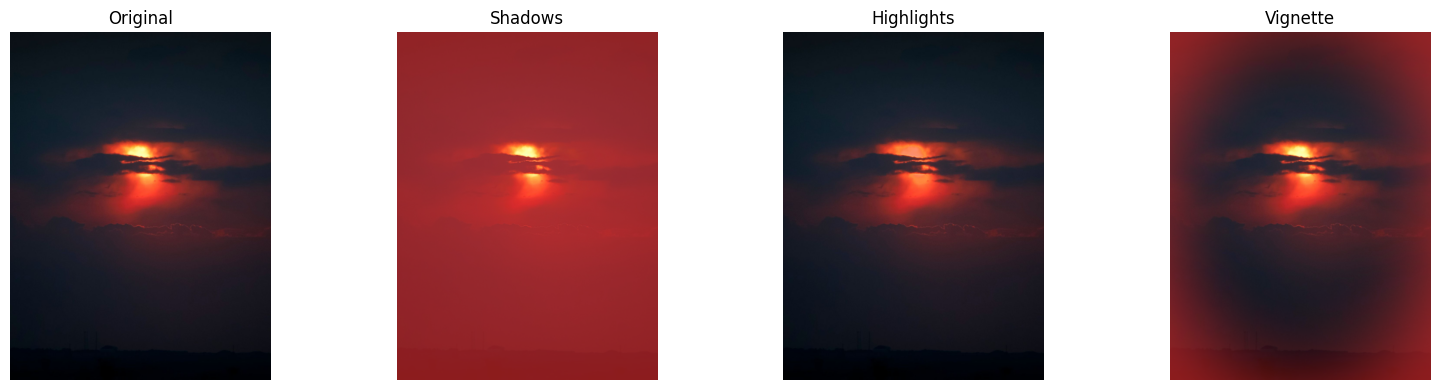

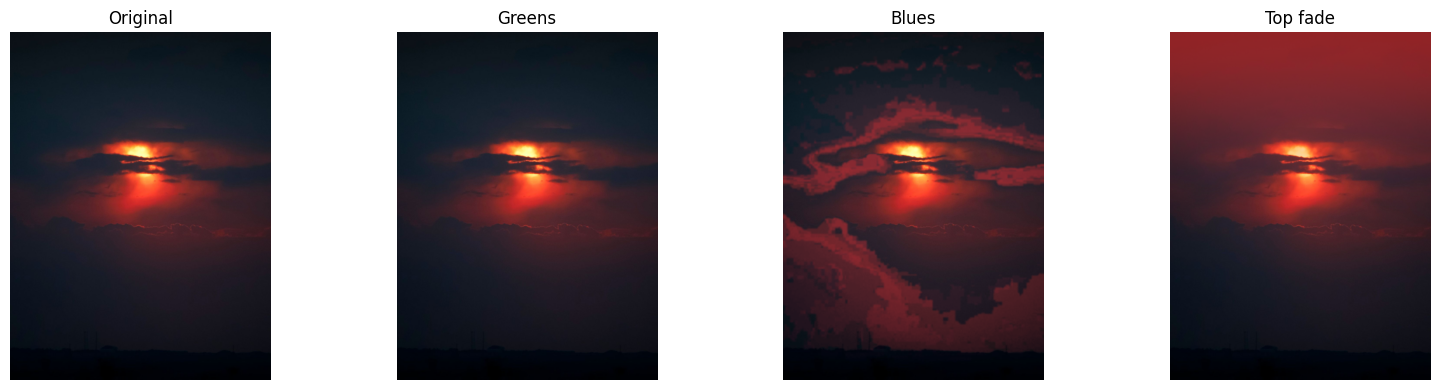

In [ ]:
import sys
sys.path.append("/content/drive/MyDrive/ai-colorist")
import importlib, masks
importlib.reload(masks)

img = small(load_image(files[0]))      # try a photo with greenery or sky for a better test

tests = {
    "Shadows":   {"type": "luminance", "range": "shadows"},
    "Highlights": {"type": "luminance", "range": "highlights"},
    "Vignette":  {"type": "vignette"},
    "Greens":    {"type": "color", "color": "green"},
    "Blues":     {"type": "color", "color": "blue"},
    "Top fade":  {"type": "gradient", "side": "top"},
}
overlays, titles = {}, {}
for name, spec in tests.items():
    m = masks.make_mask(img, spec)
    overlays[name] = masks.mask_overlay(img, m)
    print(f"{name}: covers {float(m.mean()):.0%} of the photo")

show_many([img] + [overlays[n] for n in ["Shadows", "Highlights", "Vignette"]],
          ["Original", "Shadows", "Highlights", "Vignette"])
show_many([img] + [overlays[n] for n in ["Greens", "Blues", "Top fade"]],
          ["Original", "Greens", "Blues", "Top fade"])

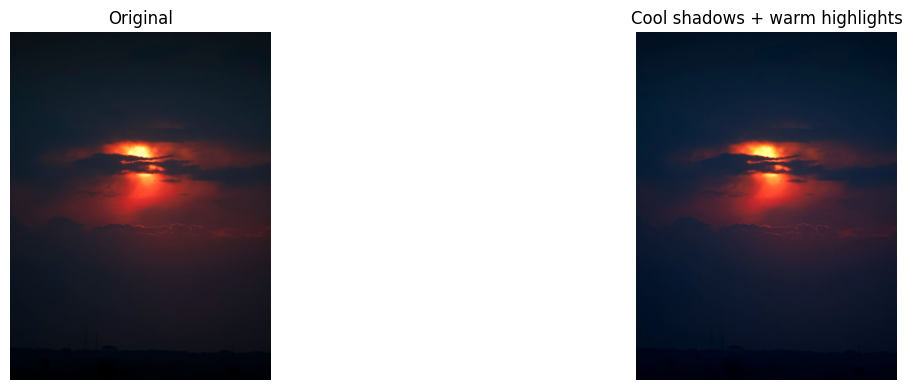

In [ ]:
shadow_m = masks.make_mask(img, {"type": "luminance", "range": "shadows"})
high_m = masks.make_mask(img, {"type": "luminance", "range": "highlights"})

cool = grade(img, temp=-0.5, wheels={"shadows": [210, 0.5]})
warm = grade(img, temp=0.5, wheels={"highlights": [35, 0.5]})

out = img + shadow_m * (cool - img)      # apply the cool grade only where the shadow mask is white
out = out + high_m * (warm - out)        # apply the warm grade only where the highlight mask is white
show_many([img, out], ["Original", "Cool shadows + warm highlights"])

In [ ]:
from google.colab import drive, userdata
drive.mount('/content/drive')
!pip install -q google-genai

import sys
sys.path.append("/content/drive/MyDrive/ai-colorist")

from colorist import *
from brain import Brain
import masks                       # <- new
import ipywidgets as widgets

masks.install()                    # <- new
files = set_folder("/content/drive/MyDrive/ai-colorist/test_images")
brain = Brain(userdata.get("GEMINI_API_KEY"))
print(len(files), "photos ready. Toolbox loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mask support installed.
22 photos ready. Toolbox loaded.


In [ ]:
PHOTO_INDEX = 0
session = Session(small(load_image(files[PHOTO_INDEX])), brain)

cmd_box = widgets.Text(placeholder="Type a command, e.g. make it moody",
                       layout=widgets.Layout(width="520px"))
strength_sl = widgets.FloatSlider(value=1.0, min=0, max=1, step=0.05, description="Strength",
                                  style={"description_width": "90px"})
skin_sl = widgets.FloatSlider(value=0.6, min=0, max=1, step=0.05, description="Skin protect",
                              style={"description_width": "90px"})
grade_btn = widgets.Button(description="Grade it", button_style="primary")
undo_btn = widgets.Button(description="Undo")
reset_btn = widgets.Button(description="Reset")
export_btn = widgets.Button(description="Export full-size", button_style="success")
out_area = widgets.Output()

def refresh():
    with out_area:
        out_area.clear_output(wait=True)
        if session.history:
            last = session.history[-1]
            print("Brain says:", last["plan"]["explanation"])
            for n in last["report"]["notes"]:
                print("Note:", n)
            print("Steps so far:", [h["command"] for h in session.history])
        show_many([session.original, session.current], ["Original", "Current"])

def on_grade(_):
    if cmd_box.value.strip():
        session.apply(cmd_box.value, strength_sl.value, skin_sl.value)
        cmd_box.value = ""
    refresh()

def on_undo(_):
    session.undo()
    refresh()

def on_reset(_):
    session.reset()
    refresh()

def on_export(_):
    with out_area:
        print("Exporting...")
        names = export_full(session, files[PHOTO_INDEX])
        print("Saved to Drive > ai-colorist > outputs:", names)

grade_btn.on_click(on_grade)
undo_btn.on_click(on_undo)
reset_btn.on_click(on_reset)
export_btn.on_click(on_export)

display(widgets.VBox([cmd_box, strength_sl, skin_sl,
                      widgets.HBox([grade_btn, undo_btn, reset_btn, export_btn]), out_area]))
refresh()

gemini-3.8-flash, attempt 1 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
gemini-3.8-flash, attempt 2 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
gemini-3.8-flash, attempt 3 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
gemini-3.7-flash, attempt 1 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
gemini-3.7-flash, attempt 2 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
gemini-3.7-flash, attempt 3 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
(used gemini-3.5-flash)


In [2]:
%%writefile /content/drive/MyDrive/ai-colorist/aimasks.py
"""aimasks.py - AI masks: name a thing ("sky", "person") and get a mask for it.
Uses Grounding DINO (text -> boxes) and SAM (boxes -> exact outline)."""
import re
import numpy as np
import cv2
from PIL import Image
import masks
import brain as _brain
from colorist import small

DINO_ID = "IDEA-Research/grounding-dino-base"
SAM_ID = "facebook/sam-vit-base"

_models = {}
_cache = {}

def _load():
    # Loads the two AI models once (the first time takes a few minutes)
    if _models:
        return
    import torch
    from transformers import AutoProcessor, AutoModel, AutoModelForZeroShotObjectDetection
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cpu":
        print("Warning: no GPU found, so AI masks will be slow. "
              "Use Runtime > Change runtime type > T4 GPU.")
    print("Loading the AI models (the first time takes a few minutes)...")
    _models["torch"] = torch
    _models["device"] = device
    _models["dino_proc"] = AutoProcessor.from_pretrained(DINO_ID)
    _models["dino"] = AutoModelForZeroShotObjectDetection.from_pretrained(DINO_ID).to(device).eval()
    _models["sam_proc"] = AutoProcessor.from_pretrained(SAM_ID)
    _models["sam"] = AutoModel.from_pretrained(SAM_ID).to(device).eval()
    print("Models ready on", device)

def find_boxes(pil, phrase, box_threshold=0.3, text_threshold=0.25):
    # Text -> boxes (Grounding DINO)
    _load()
    torch, dev = _models["torch"], _models["device"]
    proc, model = _models["dino_proc"], _models["dino"]
    text = phrase.lower().strip()
    if not text.endswith("."):
        text += "."
    inputs = proc(images=pil, text=text, return_tensors="pt").to(dev)
    with torch.no_grad():
        outputs = model(**inputs)
    sizes = [pil.size[::-1]]
    try:
        res = proc.post_process_grounded_object_detection(
            outputs, inputs.input_ids, threshold=box_threshold,
            text_threshold=text_threshold, target_sizes=sizes)[0]
    except TypeError:                       # older versions use a different name
        res = proc.post_process_grounded_object_detection(
            outputs, inputs.input_ids, box_threshold=box_threshold,
            text_threshold=text_threshold, target_sizes=sizes)[0]
    return res["boxes"].cpu(), res["scores"].cpu()

def boxes_to_mask(pil, boxes, scores, max_boxes=8):
    # Boxes -> exact outline (SAM). Combines all boxes into one mask
    _load()
    torch, dev = _models["torch"], _models["device"]
    proc, model = _models["sam_proc"], _models["sam"]
    order = scores.argsort(descending=True)[:max_boxes]
    box_list = [boxes[i].tolist() for i in order]
    inputs = proc(pil, input_boxes=[box_list], return_tensors="pt").to(dev)
    with torch.no_grad():
        try:
            outputs = model(**inputs, multimask_output=False)
        except TypeError:
            outputs = model(**inputs)
    masks_list = proc.image_processor.post_process_masks(
        outputs.pred_masks.cpu(), inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu())
    m = masks_list[0].numpy().astype(np.float32)
    m = m.reshape(m.shape[0], -1, m.shape[-2], m.shape[-1])[:, 0]
    return m.max(axis=0)

def object_mask(img, prompt, box_threshold=0.3):
    # The main function: a photo and a name in, a soft mask (H, W, 1) out
    key = (img.shape, img[::8, ::8].tobytes(), prompt, round(box_threshold, 2))
    if key in _cache:
        return _cache[key]
    work = small(img, 1024)                                  # faster on a smaller copy
    pil = Image.fromarray((np.clip(work, 0, 1) * 255).astype(np.uint8))
    boxes, scores = find_boxes(pil, prompt, box_threshold)
    if len(boxes) == 0:
        mask = np.zeros(img.shape[:2], np.float32)
        print(f"[AI mask '{prompt}': found nothing. Try box_threshold=0.2]")
    else:
        m = boxes_to_mask(pil, boxes, scores)
        mask = cv2.resize(m, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_LINEAR)
        print(f"[AI mask '{prompt}': {len(boxes)} object(s), covers {float(mask.mean()):.0%}]")
    out = masks.soft(mask[..., None].astype(np.float32), 0.01)   # soft edges
    _cache[key] = out
    return out

# ---------- Plugging AI masks into the masks module and the brain ----------
def clean_mask_v2(spec):
    if isinstance(spec, dict) and spec.get("type") == "object":
        prompt = re.sub(r"[^a-z \-]", "", str(spec.get("prompt", "")).lower()).strip()[:40]
        if not prompt:
            return None
        out = {"type": "object", "prompt": prompt}
        if spec.get("invert") is True:
            out["invert"] = True
        return out
    return masks._orig_clean_mask(spec)

def make_mask_v2(img, spec):
    if spec.get("type") == "object":
        m = object_mask(img, spec["prompt"])
        return 1 - m if spec.get("invert") else m
    return masks._orig_make_mask(img, spec)

OBJECT_RULES = """
9. Objects: the mask type {"type": "object", "prompt": "sky"} now works for named things in the photo, for example sky, person, face, hair, grass, trees, water, building, car, shirt. Use a short lowercase noun phrase of 1 to 3 words. To edit everything EXCEPT something, use "invert": true (for example the background = {"type": "object", "prompt": "person", "invert": true}). Rules 6 and the sky/people note in rule 8 no longer apply: use object masks for sky, people, faces and objects. For a request about one thing, put the changes in "regions" with that mask. Keep the same taste rules: subtle values.
Example request: "make the sky bluer and a bit darker". Example reply: {"settings": {}, "regions": [{"mask": {"type": "object", "prompt": "sky"}, "settings": {"temp": -0.25, "saturation_amt": 0.2, "exposure_stops": -0.15}}], "preset": null, "preset_strength": 1.0, "explanation": "Made the sky bluer, richer and slightly darker."}
"""

def install():
    masks.install()                          # makes sure region support is in place
    if not hasattr(masks, "_orig_make_mask"):
        masks._orig_make_mask = masks.make_mask
        masks._orig_clean_mask = masks.clean_mask
    masks.make_mask = make_mask_v2
    masks.clean_mask = clean_mask_v2
    _brain.SYSTEM_TEMPLATE = _brain._orig_template + masks.MASK_RULES + OBJECT_RULES
    print("AI mask support installed.")

Writing /content/drive/MyDrive/ai-colorist/aimasks.py


In [3]:
from google.colab import drive, userdata
drive.mount('/content/drive')
!pip install -q google-genai
!pip install -q -U transformers accelerate      # <- new

import sys
sys.path.append("/content/drive/MyDrive/ai-colorist")

from colorist import *
from brain import Brain
import masks
import aimasks                                   # <- new
import ipywidgets as widgets

aimasks.install()                                # <- new (also installs the classic masks)
files = set_folder("/content/drive/MyDrive/ai-colorist/test_images")
brain = Brain(userdata.get("GEMINI_API_KEY"))
print(len(files), "photos ready. Toolbox loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mask support installed.
AI mask support installed.
22 photos ready. Toolbox loaded.


Loading the AI models (the first time takes a few minutes)...


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Models ready on cuda
[AI mask 'sky': 1 object(s), covers 89%]


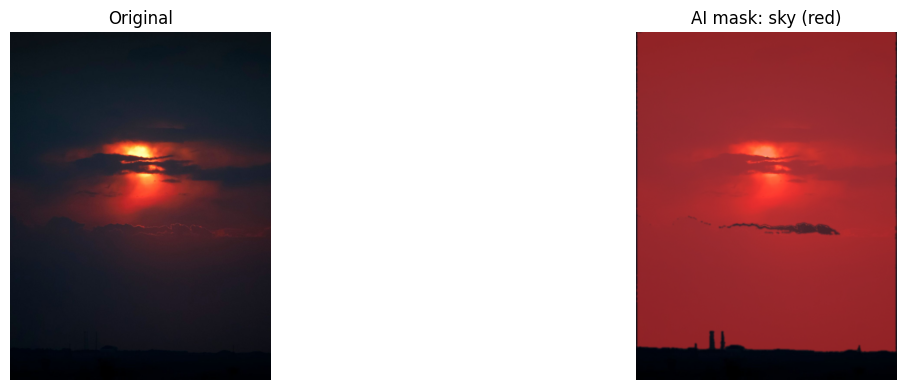

In [4]:
PHOTO_INDEX = 0
img = small(load_image(files[PHOTO_INDEX]))
m = aimasks.object_mask(img, "sky")
show_many([img, masks.mask_overlay(img, m)], ["Original", "AI mask: sky (red)"])

[AI mask 'person': found nothing. Try box_threshold=0.2]
[AI mask 'trees': found nothing. Try box_threshold=0.2]


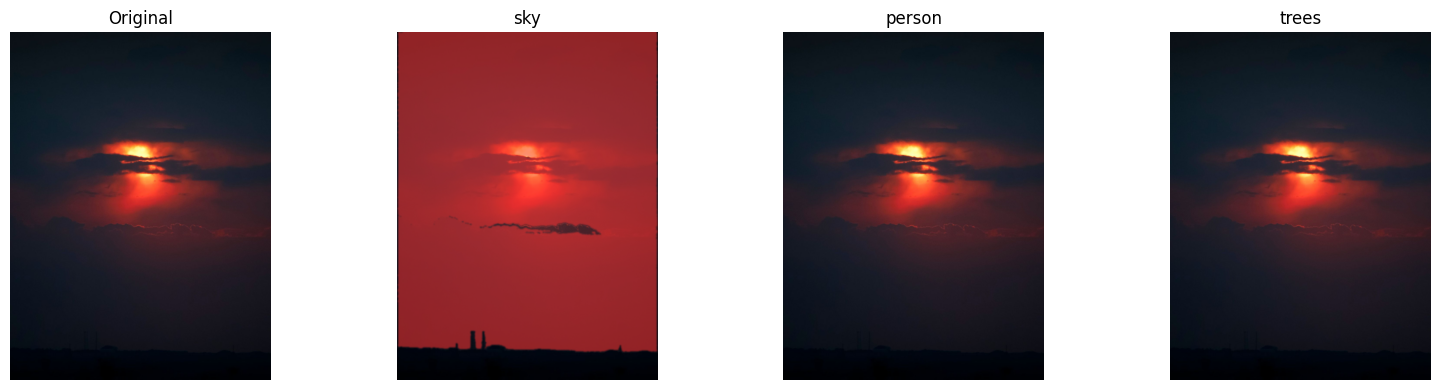

[AI mask 'water': 1 object(s), covers 8%]
[AI mask 'building': found nothing. Try box_threshold=0.2]
[AI mask 'grass': 1 object(s), covers 8%]


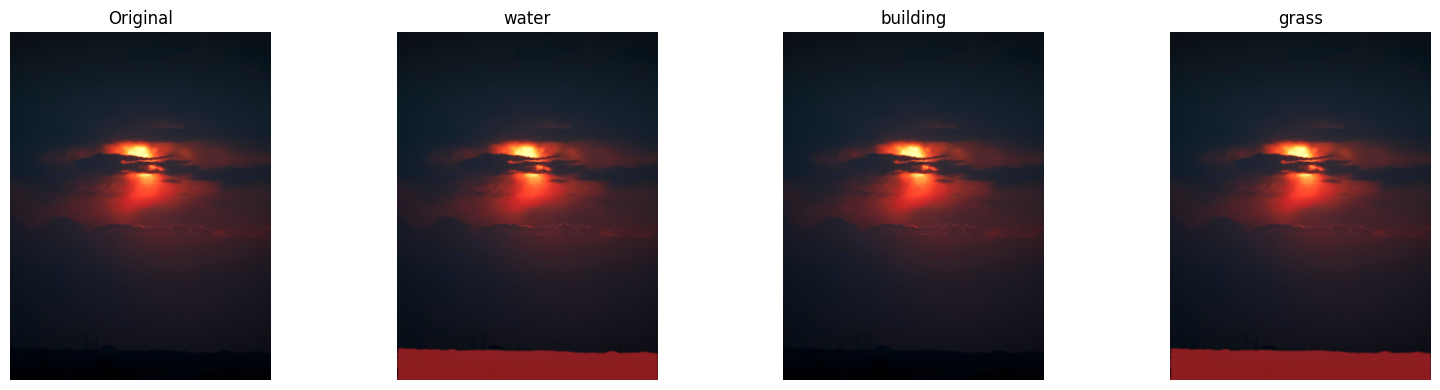

In [5]:
def try_prompts(img, prompts):
    shown = [img]
    for p in prompts:
        shown.append(masks.mask_overlay(img, aimasks.object_mask(img, p)))
    show_many(shown, ["Original"] + prompts)

try_prompts(img, ["sky", "person", "trees"])
try_prompts(img, ["water", "building", "grass"])

In [3]:
%%writefile /content/drive/MyDrive/ai-colorist/aimasks.py
"""aimasks.py - AI masks (Grounding DINO + SAM) and mask refinement tools."""
import re
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import masks
import colorist
import brain as _brain
from colorist import small

DINO_ID = "IDEA-Research/grounding-dino-base"
SAM_ID = "facebook/sam-vit-base"

_models = {}
_cache = {}

# ---------- Loading the two AI models ----------
def _load():
    if _models:
        return
    import torch
    from transformers import AutoProcessor, AutoModel, AutoModelForZeroShotObjectDetection
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device == "cpu":
        print("Warning: no GPU found, so AI masks will be slow. "
              "Use Runtime > Change runtime type > T4 GPU.")
    print("Loading the AI models (the first time takes a few minutes)...")
    _models["torch"] = torch
    _models["device"] = device
    _models["dino_proc"] = AutoProcessor.from_pretrained(DINO_ID)
    _models["dino"] = AutoModelForZeroShotObjectDetection.from_pretrained(DINO_ID).to(device).eval()
    _models["sam_proc"] = AutoProcessor.from_pretrained(SAM_ID)
    _models["sam"] = AutoModel.from_pretrained(SAM_ID).to(device).eval()
    print("Models ready on", device)

# ---------- Text -> boxes (Grounding DINO) ----------
def find_boxes(pil, phrase, box_threshold=0.3, text_threshold=0.25):
    _load()
    torch, dev = _models["torch"], _models["device"]
    proc, model = _models["dino_proc"], _models["dino"]
    text = phrase.lower().strip()
    if not text.endswith("."):
        text += "."
    inputs = proc(images=pil, text=text, return_tensors="pt").to(dev)
    with torch.no_grad():
        outputs = model(**inputs)
    sizes = [pil.size[::-1]]
    try:
        res = proc.post_process_grounded_object_detection(
            outputs, inputs.input_ids, threshold=box_threshold,
            text_threshold=text_threshold, target_sizes=sizes)[0]
    except TypeError:
        res = proc.post_process_grounded_object_detection(
            outputs, inputs.input_ids, box_threshold=box_threshold,
            text_threshold=text_threshold, target_sizes=sizes)[0]
    return res["boxes"].cpu(), res["scores"].cpu()

# ---------- Boxes or points -> exact outlines (SAM) ----------
def _run_sam(pil, **prompt):
    _load()
    torch, dev = _models["torch"], _models["device"]
    proc, model = _models["sam_proc"], _models["sam"]
    inputs = proc(pil, return_tensors="pt", **prompt).to(dev)
    with torch.no_grad():
        try:
            outputs = model(**inputs, multimask_output=False)
        except TypeError:
            outputs = model(**inputs)
    result = proc.image_processor.post_process_masks(
        outputs.pred_masks.cpu(), inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu())[0].numpy().astype(np.float32)
    return result.reshape(result.shape[0], -1, result.shape[-2], result.shape[-1])[:, 0]

def boxes_to_mask(pil, boxes, scores, max_boxes=8):
    order = scores.argsort(descending=True)[:max_boxes]
    box_list = [boxes[i].tolist() for i in order]
    return _run_sam(pil, input_boxes=[box_list]).max(axis=0)

def point_mask(pil, x_norm, y_norm):
    w, h = pil.size
    return _run_sam(pil, input_points=[[[x_norm * w, y_norm * h]]])[0]

# ---------- The main function: a photo and a name in, a mask out ----------
def object_mask(img, prompt, box_threshold=0.3, add=None, remove=None):
    # add / remove = lists of [x, y] spots, each between 0 and 1 (fractions of the picture)
    add, remove = add or [], remove or []
    key = (img.shape, img[::8, ::8].tobytes(), prompt, round(box_threshold, 2),
           tuple(map(tuple, add)), tuple(map(tuple, remove)))
    if key in _cache:
        return _cache[key]
    work = small(img, 1024)
    pil = Image.fromarray((np.clip(work, 0, 1) * 255).astype(np.uint8))
    boxes, scores = find_boxes(pil, prompt, box_threshold)
    if len(boxes) == 0:
        m = np.zeros(work.shape[:2], np.float32)
        print(f"[AI mask '{prompt}': found nothing. Try box_threshold=0.2]")
    else:
        m = boxes_to_mask(pil, boxes, scores)
        print(f"[AI mask '{prompt}': {len(boxes)} object(s), covers {float(m.mean()):.0%}]")
    for x, y in add:
        m = np.maximum(m, point_mask(pil, x, y))
    for x, y in remove:
        m = m * (1 - point_mask(pil, x, y))
    out = cv2.resize(m, (img.shape[1], img.shape[0]),
                     interpolation=cv2.INTER_LINEAR)[..., None].astype(np.float32)
    _cache[key] = out
    return out

# ---------- Refinement tools ----------
def refine(m, grow=0.0, feather=0.0):
    # grow: percent of picture size (positive expands, negative shrinks); feather: edge softness in percent
    h, w = m.shape[:2]
    side = min(h, w)
    g = float(grow or 0)
    if abs(g) >= 0.05:
        r = max(1, int(round(abs(g) / 100.0 * side)))
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))
        m2 = m[..., 0]
        m2 = cv2.dilate(m2, kernel) if g > 0 else cv2.erode(m2, kernel)
        m = m2[..., None]
    if feather and feather > 0:
        m = masks.soft(m, float(feather) / 100.0)
    return np.clip(m, 0, 1).astype(np.float32)

def make_mask_v2(img, spec):
    if spec.get("type") == "object":
        m = object_mask(img, spec["prompt"], add=spec.get("add"), remove=spec.get("remove"))
        feather = spec.get("feather", 1.0)          # objects get a gentle soft edge by default
    else:
        m = masks._orig_make_mask(img, dict(spec, invert=False))
        feather = spec.get("feather", 0.0)
    m = refine(m, spec.get("grow", 0.0), feather)
    return 1 - m if spec.get("invert") else m

# ---------- Checking what the brain (or you) ask for ----------
def clean_points(raw):
    out = []
    if isinstance(raw, list):
        for p in raw[:6]:
            try:
                x, y = p
                out.append([round(_brain.num(x, 0, 1), 3), round(_brain.num(y, 0, 1), 3)])
            except (TypeError, ValueError):
                pass
    return out

def clean_mask_v2(spec):
    if isinstance(spec, dict) and spec.get("type") == "object":
        prompt = re.sub(r"[^a-z \-]", "", str(spec.get("prompt", "")).lower()).strip()[:40]
        if not prompt:
            return None
        out = {"type": "object", "prompt": prompt}
        if spec.get("invert") is True:
            out["invert"] = True
    else:
        out = masks._orig_clean_mask(spec)
        if out is None:
            return None
    if isinstance(spec, dict):
        if spec.get("grow") is not None:
            out["grow"] = round(_brain.num(spec["grow"], -5, 5), 2)
        if spec.get("feather") is not None:
            out["feather"] = round(_brain.num(spec["feather"], 0, 10), 2)
        for key in ("add", "remove"):
            pts = clean_points(spec.get(key))
            if pts:
                out[key] = pts
    return out

# ---------- Helpers for refining by hand ----------
def show_grid(img, title=""):
    # Shows a picture with a percent grid, so you can read positions
    h, w = img.shape[:2]
    plt.figure(figsize=(9, 6))
    plt.imshow(np.clip(img, 0, 1), extent=[0, 100, 100, 0], aspect=h / w)
    plt.xticks(range(0, 101, 10))
    plt.yticks(range(0, 101, 10))
    plt.grid(color="white", alpha=0.45, linewidth=0.8)
    plt.xlabel("x (% from the left)")
    plt.ylabel("y (% from the top)")
    plt.title(title)
    plt.show()

def _step_base(session, index=-1):
    i = index if index >= 0 else len(session.history) + index
    return session.history[i - 1]["image"] if i > 0 else session.original

def show_region(session, region=0):
    if not session.history:
        print("Run a command first.")
        return
    regions = session.history[-1]["plan"].get("regions", [])
    if region >= len(regions):
        print(f"The last edit has {len(regions)} region(s), so region {region} does not exist.")
        return
    base = _step_base(session)
    spec = regions[region]["mask"]
    m = masks.make_mask(base, spec)
    show_grid(masks.mask_overlay(base, m),
              "Mask of region " + str(region) + ": " + str(spec.get("prompt") or spec.get("type")))

def refine_last(session, region=0, add=None, remove=None, grow=None, feather=None, clear_points=False):
    # add / remove: lists of [x, y] in PERCENT, e.g. add=[[62, 18]]
    if not session.history:
        print("Run a command first.")
        return
    step = session.history[-1]
    regions = step["plan"].get("regions", [])
    if region >= len(regions):
        print(f"The last edit has {len(regions)} region(s), so region {region} does not exist.")
        return
    spec = regions[region]["mask"]
    if (add or remove) and spec.get("type") != "object":
        print("Points only work on AI object masks, not on brightness or colour masks.")
        return
    to_norm = lambda pts: clean_points([[x / 100.0, y / 100.0] for x, y in (pts or [])])
    if clear_points:
        spec.pop("add", None)
        spec.pop("remove", None)
    if add:
        spec["add"] = (spec.get("add", []) + to_norm(add))[:6]
    if remove:
        spec["remove"] = (spec.get("remove", []) + to_norm(remove))[:6]
    if grow is not None:
        spec["grow"] = round(_brain.num(grow, -5, 5), 2)
    if feather is not None:
        spec["feather"] = round(_brain.num(feather, 0, 10), 2)
    base = _step_base(session)
    full = colorist.build_edit(base, step["plan"])
    step["image"], step["report"] = colorist.safe_finish(base, full, step["strength"], step["skin"])

# ---------- Plugging everything into the masks module and the brain ----------
OBJECT_RULES = """
9. Objects: the mask type {"type": "object", "prompt": "sky"} works for named things in the photo, for example sky, person, face, hair, grass, trees, water, building, car, shirt. Use a short lowercase noun phrase of 1 to 3 words. To edit everything EXCEPT something, use "invert": true (for example the background = {"type": "object", "prompt": "person", "invert": true}). Rule 6 and the sky/people note in rule 8 no longer apply: use object masks for sky, people, faces and objects. For a request about one thing, put the changes in "regions" with that mask. Keep the same taste rules: subtle values.
Example request: "make the sky bluer and a bit darker". Example reply: {"settings": {}, "regions": [{"mask": {"type": "object", "prompt": "sky"}, "settings": {"temp": -0.25, "saturation_amt": 0.2, "exposure_stops": -0.15}}], "preset": null, "preset_strength": 1.0, "explanation": "Made the sky bluer, richer and slightly darker."}
"""

REFINE_RULES = """
10. Mask refinement: any mask may include "grow" (-5 to 5, a percent of the picture size: positive expands the mask, negative shrinks it) and "feather" (0 to 10, how soft the edge is; objects already get about 1). Use them only when the user asks: "softer edges" or "blend it more" means feather 4 to 8; "tighter" means grow -1 to -2; "include a bit more around it" means grow 1 to 2. Never output "add" or "remove": the user sets those by hand.
"""

def install():
    masks.install()
    if not hasattr(masks, "_orig_make_mask"):
        masks._orig_make_mask = masks.make_mask
        masks._orig_clean_mask = masks.clean_mask
    masks.make_mask = make_mask_v2
    masks.clean_mask = clean_mask_v2
    _brain.SYSTEM_TEMPLATE = _brain._orig_template + masks.MASK_RULES + OBJECT_RULES + REFINE_RULES
    print("AI mask and refinement support installed.")

Overwriting /content/drive/MyDrive/ai-colorist/aimasks.py


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
folder = "/content/drive/MyDrive/ai-colorist"
print("Folder exists:", os.path.exists(folder))
if os.path.exists(folder):
    print(sorted(os.listdir(folder)))

Mounted at /content/drive
Folder exists: True
['__pycache__', 'aimasks.py', 'brain.py', 'colorist.py', 'masks.py', 'outputs', 'presets.json', 'test_images']


In [4]:
print(sorted(os.listdir("/content/drive/MyDrive/ai-colorist")))

['__pycache__', 'aimasks.py', 'brain.py', 'colorist.py', 'masks.py', 'outputs', 'presets.json', 'test_images']


In [5]:
from google.colab import drive, userdata
drive.mount('/content/drive')
import os                                                              # <- new
os.environ["HF_HOME"] = "/content/drive/MyDrive/ai-colorist/hf_cache"  # <- new
!pip install -q google-genai
!pip install -q -U transformers accelerate

import sys
sys.path.append("/content/drive/MyDrive/ai-colorist")

from colorist import *
from brain import Brain
import masks
import aimasks
import ipywidgets as widgets

aimasks.install()
files = set_folder("/content/drive/MyDrive/ai-colorist/test_images")
brain = Brain(userdata.get("GEMINI_API_KEY"))
print(len(files), "photos ready. Toolbox loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mask support installed.
AI mask and refinement support installed.
22 photos ready. Toolbox loaded.


In [7]:
PHOTO_INDEX = 0
session = Session(small(load_image(files[PHOTO_INDEX])), brain)

cmd_box = widgets.Text(placeholder="Type a command, e.g. make it moody",
                       layout=widgets.Layout(width="520px"))
strength_sl = widgets.FloatSlider(value=1.0, min=0, max=1, step=0.05, description="Strength",
                                  style={"description_width": "90px"})
skin_sl = widgets.FloatSlider(value=0.6, min=0, max=1, step=0.05, description="Skin protect",
                              style={"description_width": "90px"})
grade_btn = widgets.Button(description="Grade it", button_style="primary")
undo_btn = widgets.Button(description="Undo")
reset_btn = widgets.Button(description="Reset")
export_btn = widgets.Button(description="Export full-size", button_style="success")
out_area = widgets.Output()

def refresh():
    with out_area:
        out_area.clear_output(wait=True)
        if session.history:
            last = session.history[-1]
            print("Brain says:", last["plan"]["explanation"])
            for n in last["report"]["notes"]:
                print("Note:", n)
            print("Steps so far:", [h["command"] for h in session.history])
        show_many([session.original, session.current], ["Original", "Current"])

def on_grade(_):
    if cmd_box.value.strip():
        session.apply(cmd_box.value, strength_sl.value, skin_sl.value)
        cmd_box.value = ""
    refresh()

def on_undo(_):
    session.undo()
    refresh()

def on_reset(_):
    session.reset()
    refresh()

def on_export(_):
    with out_area:
        print("Exporting...")
        names = export_full(session, files[PHOTO_INDEX])
        print("Saved to Drive > ai-colorist > outputs:", names)

grade_btn.on_click(on_grade)
undo_btn.on_click(on_undo)
reset_btn.on_click(on_reset)
export_btn.on_click(on_export)

display(widgets.VBox([cmd_box, strength_sl, skin_sl,
                      widgets.HBox([grade_btn, undo_btn, reset_btn, export_btn]), out_area]))
refresh()

gemini-3.8-flash, attempt 1 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
gemini-3.8-flash, attempt 2 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.8-flash, attempt 3 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand 
gemini-3.7-flash, attempt 1 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.7-flash, attempt 2 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.7-flash, attempt 3 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.5-flash, attempt 1 failed: 503 UNAVAILABLE. {'err

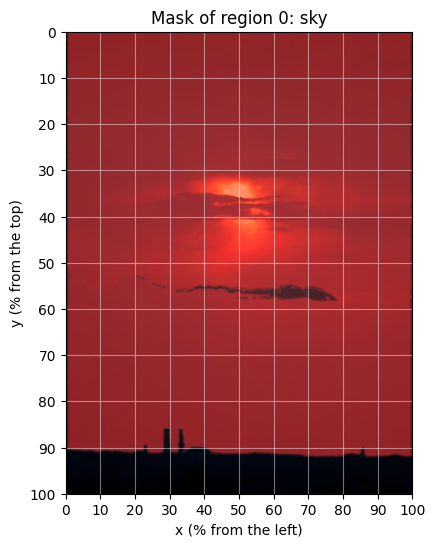

In [12]:
aimasks.show_region(session)

In [9]:
import time
plt.close('all')

step = session.history[-1]
spec = step["plan"]["regions"][0]["mask"]
base = aimasks._step_base(session)

t = time.time(); m = masks.make_mask(base, spec)
print("1) mask, first call:", round(time.time() - t, 1), "seconds")

t = time.time(); m = masks.make_mask(base, spec)
print("2) mask, second call:", round(time.time() - t, 1), "seconds")

t = time.time(); aimasks.show_grid(masks.mask_overlay(base, m), "test")
print("3) drawing:", round(time.time() - t, 1), "seconds")

print("Models running on:", aimasks._models.get("device"))
print("Masks remembered:", len(aimasks._cache))

IndexError: list index out of range

In [10]:
import time
t = time.time()
plan, report = session.apply("make the sky bluer and a bit darker")
print("Took", round(time.time() - t), "seconds")
print("Brain says:", plan["explanation"])
print("Regions:", json.dumps(plan.get("regions"), indent=1))
print("Notes:", report["notes"])
print("Models ran on:", aimasks._models.get("device"))

gemini-3.8-flash, attempt 1 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.8-flash, attempt 2 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.8-flash, attempt 3 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.7-flash, attempt 1 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.7-flash, attempt 2 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.7-flash, attempt 3 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and 
gemini-3.5-flash, attempt 1 failed: 503 UNAVAILABLE. {'err

In [4]:
import time
t = time.time()
aimasks._load()
print("Loaded in", round(time.time() - t), "seconds")

Loading the AI models (the first time takes a few minutes)...


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.74k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

... (6 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Models ready on cuda
Loaded in 40 seconds


In [11]:
brain.models = ["gemini-3.1-flash-lite", "gemini-3.5-flash", "gemini-3.7-flash", "gemini-3.8-flash"]

[AI mask 'sky': 1 object(s), covers 89%]
[AI mask 'sky': 1 object(s), covers 89%]


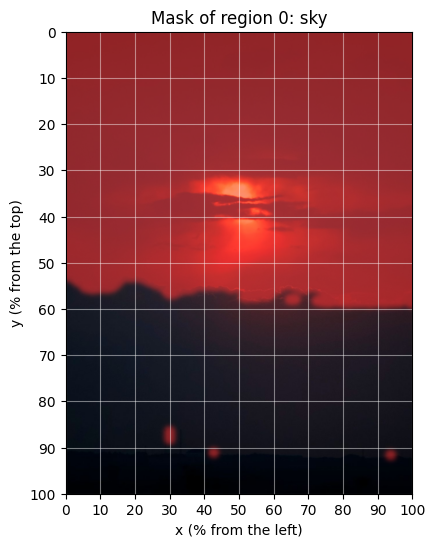

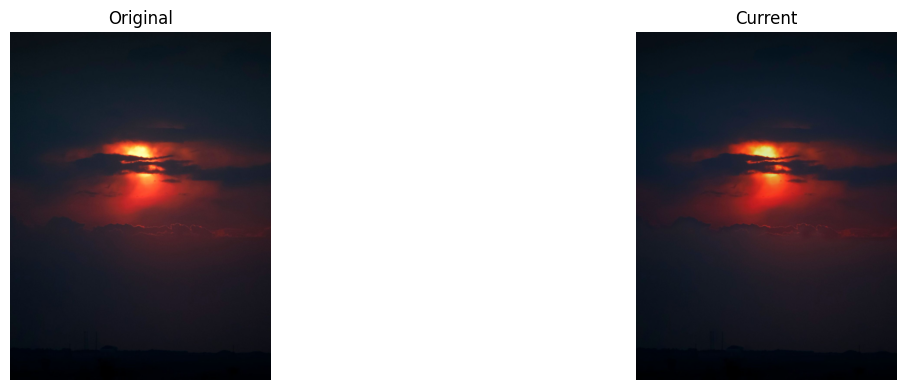

In [13]:
# 1. Add a missed spot. Point at it with x% and y%
aimasks.refine_last(session, add=[[62, 18]])

# 2. Remove something that was wrongly included
aimasks.refine_last(session, remove=[[30, 80]])

# 3. Grow the mask by about 1.5% and soften the edge
aimasks.refine_last(session, grow=1.5, feather=4)

# See the result: the mask, and then the edited photo
aimasks.show_region(session)
show_many([session.original, session.current], ["Original", "Current"])

In [14]:
x_box = widgets.BoundedFloatText(value=50, min=0, max=100, step=1, description="x %",
                                 layout=widgets.Layout(width="150px"))
y_box = widgets.BoundedFloatText(value=50, min=0, max=100, step=1, description="y %",
                                 layout=widgets.Layout(width="150px"))
region_box = widgets.BoundedIntText(value=0, min=0, max=3, description="Region",
                                    layout=widgets.Layout(width="150px"))
grow_sl = widgets.FloatSlider(value=0, min=-5, max=5, step=0.5, description="Grow",
                              style={"description_width": "70px"})
feather_sl = widgets.FloatSlider(value=1, min=0, max=10, step=0.5, description="Feather",
                                 style={"description_width": "70px"})
add_btn = widgets.Button(description="Add this spot", button_style="success")
remove_btn = widgets.Button(description="Remove this spot", button_style="danger")
apply_btn = widgets.Button(description="Apply grow + feather")
show_btn = widgets.Button(description="Show mask")
out2 = widgets.Output()

def show_both():
    with out2:
        out2.clear_output(wait=True)
        aimasks.show_region(session, region_box.value)
        show_many([session.original, session.current], ["Original", "Current"])

def on_add(_):
    aimasks.refine_last(session, region=region_box.value, add=[[x_box.value, y_box.value]])
    show_both()

def on_remove(_):
    aimasks.refine_last(session, region=region_box.value, remove=[[x_box.value, y_box.value]])
    show_both()

def on_apply(_):
    aimasks.refine_last(session, region=region_box.value, grow=grow_sl.value, feather=feather_sl.value)
    show_both()

add_btn.on_click(on_add)
remove_btn.on_click(on_remove)
apply_btn.on_click(on_apply)
show_btn.on_click(lambda _: show_both())

display(widgets.VBox([
    widgets.HBox([x_box, y_box, region_box]),
    widgets.HBox([add_btn, remove_btn, show_btn]),
    grow_sl, feather_sl, apply_btn, out2]))

In [15]:
names = export_full(session, files[PHOTO_INDEX])
print("Saved:", names)

[AI mask 'sky': 1 object(s), covers 90%]
Saved: ('graded_photo1.jpg', 'recipe_photo1.json')
